[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/04_Botnet_DGA_Detection/QOCSVM_MalwareBeaconing_Micah2026.ipynb)

# Quantum-kernel one-class SVM for malware-beaconing detection: Micah et al. (2026) step by step

**Paper.** Boaz Micah, Nadia Milazzo, Maissa Beji, Borja Aizpurua, Llorenc Espinosa-Portales, Esteban Payares, Ghada Ben Slama, Luc Andrea, Michel Kurek, Thomas Cope and Olivier Salomon,
*Pareto-optimal quantum kernel selection for unsupervised anomaly detection on real malware beaconing data*, arXiv:2610.09717v1 [quant-ph], 7 October 2026.

**What this notebook does.** It rebuilds the paper's protocol end to end on public data:

1. it downloads real botnet traffic (CTU-13 botnet-only captures) and real normal traffic (Stratosphere normal captures), turns packets into per-flow statistics and keeps the paper's six features;
2. it trains a **one-class SVM (OCSVM) with a quantum kernel** (fidelity kernel or projected kernel) on 200 *normal* flows only;
3. it chooses the kernel **without labels**, using the normalised pseudo-discrepancy (**NPD**) as a quality proxy and the **geometric difference (GD)** to a tuned classical RBF kernel as a separation measure, alone or jointly on a **Pareto front** (the *knee point* is the compromise);
4. only afterwards it uses the labels, to measure AUC and F1 on a held-out test set that contains the botnet flows;
5. it compares every number with the paper and gives a verdict per claim.

**How to run.** Colab: *Runtime -> Change runtime type -> CPU*, then *Runtime -> Run all*. The first cell installs pinned packages (a session restart may be needed once).
The committed outputs come from a `FAST_MODE = False` run (the paper's budgets: 100 trials, 150 for the fidelity kernel; five seeds), about 8 minutes on one CPU thread after the one-to-two-minute data download. `FAST_MODE = True` is the short class demo (one seed, small search budgets, about 4 minutes). All simulations are exact statevector simulations on the CPU; no quantum hardware or account is needed.

**What you get at the end.** The Pareto fronts, the GD-versus-AUC and NPD-versus-AUC plots (the paper's Figures 2-4), the tables of the selected kernels (Tables IV-VI), drawings of the executed circuits, a tuned classical baseline on identical inputs, and a claim-by-claim comparison table.

## The paper in one page

**Problem.** Malware *beaconing* is the periodic call-home of an infected host to its command-and-control (C&C) server. Labelled examples are scarce and age quickly, so detection must be **unsupervised**: the model sees only normal traffic, and even its hyper-parameters must be chosen without labels.

**Decision.** A flow is flagged anomalous when the OCSVM decision value is negative. Quality is measured by AUC and by F1 with the anomaly as positive class, F1(A), and with the normal flows as positive class, F1(N).

**Method.**
- *Kernels.* Fidelity kernel `k(x, x') = |<phi(x')|phi(x)>|^2` and projected kernel `k(x, x') = exp(-gamma * sum_k ||rho_k(x) - rho_k(x')||_F^2)` (one-qubit reduced density matrices `rho_k`). Both feed a classical OCSVM with a precomputed kernel.
- *Four data encodings* (Appendix A): `Z` (separable), `IQP`, `Hamiltonian` (Trotterised `exp(-i t x_j (XX+YY+ZZ))`, n+1 qubits) and `CNOT` (hardware-inspired), each with 1-5 layers.
- *NPD (label-free quality proxy).* Train on part of the training flows, then compare the anomaly scores of a held-out *validation* part with those of *generated* points drawn from an axis-aligned Gaussian fitted to the training part: `NPD = (mean(s_gen) - mean(s_val))^2 / (2 (var(s_gen) + var(s_val)) + eps)`. Large NPD means the model separates real normal data from synthetic out-of-distribution data.
- *GD (separation from a classical kernel).* `g_C->Q = sqrt(|| sqrt(K_Q) K_C^-1 sqrt(K_Q) ||_inf)` with both Gram matrices normalised to trace N. If `g << sqrt(N)` a classical model is guaranteed to do about as well as the quantum one (Huang et al., 2021).
- *Search.* Optuna: NSGA-II for the joint (NPD, GD) objective, TPE for each single objective; 100 trials (150 for the fidelity kernel). The Pareto knee is the front point closest to the utopia point (1, 1) after rescaling both objectives to [0, 1].

**Data.** CTU-13 botnet captures plus Stratosphere normal captures; flows keyed by (source IP, destination IP, protocol, external port); six features (Table II): forward and backward packets per second, std of the FFT of the forward traffic, std of the forward inter-arrival time, std of packet lengths, mean forward packet length. Training: 200 normal flows. Test: 1,000 flows (457 anomalous, 543 normal); simulator scores are aggregated per source-destination pair (lowest score kept), giving 777 evaluation samples (255 anomalous, 522 normal).

**Claims to check.** Tuned classical OCSVM AUC 0.765. NPD-selected fidelity kernel AUC 0.840 with `g` about 4.3, below `sqrt(N) = 14.14`, so the gain cannot be certified as quantum. Projected kernels reach much larger `g` (up to 272); the Pareto-selected one has AUC 0.782 with `g` about 89. Simulator-with-noise and IQM Garnet hardware results (Tables VI, VII) are also reported.

## What follows the paper and what had to be chosen

The paper's flow table is not public, and several implementation details are not given. Every choice is marked `# CHOICE:` in the code below.

| Item | Paper | This notebook |
|---|---|---|
| Traffic source | CTU-13 (13 scenarios) + Stratosphere normal captures, private flow table | Same projects, public files: botnet-only pcaps of six CTU-13 scenarios (Botnet-42, 43, 46, 47, 48, 49) and eleven Stratosphere normal captures (CTU-Normal-14, 18, 20, 23-29, 31); pcaps are downloaded partially (HTTP Range, below 50 MB each) and turned into flows inside the notebook |
| Anomalous flows | flows of the botnet, selected with the list of control IP addresses | all flows between the infected CTU-13 host (147.32.84.165) and external (public) addresses; the botnet-only pcaps contain no other host, no separate C&C-only list is used (so spam / click-fraud flows are included) |
| Flow definition | (source IP, destination IP, protocol, external port) | (local host, remote IP, protocol, service port = lower of the two ports); only public remote addresses; at least 2 packets |
| Six features | picked by hierarchical clustering + silhouette from ~40 candidates | the same six features (Table II), computed from the packets; the clustering step is not rerun; FFT = magnitude spectrum of the forward byte count in 1-second bins; flow duration floored at 1 ms |
| Sizes | 200 normal training flows; 1,000 test flows (457 + 543); 777 pair-aggregated samples | 200 / 543 / 457 exactly; the pair-aggregated size is printed (it depends on the sample) |
| Feature scaling | not stated | `log1p`, then MinMax to [0, pi] fitted on the training flows, test angles clipped to [0, pi] |
| Classical reference | RBF OCSVM tuned by NPD (gamma 8.99, nu 0.472) | RBF OCSVM, gamma in [1e-3, 100] (log), nu in [0.01, 1], tuned by NPD with TPE on the same inputs |
| NPD sets | train split into train/validation, generated set of the same size | 160 / 40 split, 40 generated points, Gaussian sampled in the scaled feature space and clipped to [0, pi] |
| GD | `K_C` = tuned classical kernel, both traces equal N | same; `K_C^-1` regularised with a jitter of 1e-8 |
| Encodings | Appendix A (some typesetting lost in the PDF) | IQP phase `exp(-i/2 (sum x_j Z_j + sum x_j x_k Z_j Z_k))`; Hamiltonian map: n+1 qubits, `t = 1`, `T` Trotter steps = number of layers, fixed random initial single-qubit states, couplings applied in order j = 1..n; CNOT map: Hadamards, `RZ(x_j)`, CNOT ladder per layer |
| Search | Optuna NSGA-II (joint) and TPE (single) | own compact NSGA-II (population 20) and univariate TPE with the same search space (Table I) and the same budgets in the full run |
| GD-selected kernel and nu | `nu` undefined for the GD objective | `nu` of the GD-selected kernel is chosen by NPD (label-free) |
| Metrics | AUC, F1(A), F1(N), per source-destination pair on simulators | the same, per pair (primary, "pair") and per flow ("flow") |
| Noisy simulator / IQM Garnet | Tables VI (lower half), VII | not run here (no IQM backend or noise model): **cannot be checked** |
| Repetitions | one run | FAST: one seed; full: five seeds, mean +- std |

In [1]:
import sys, subprocess, importlib.util
IN_COLAB = "google.colab" in sys.modules
_needed = ["qiskit", "qiskit_machine_learning", "sklearn", "pylatexenc", "scipy"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in _needed):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc"], check=True)
    print("Installed the pinned packages. If an import below fails, restart the session once (Runtime > Restart session) and run all cells again.")
else:
    print("Packages already available, nothing installed.")

Packages already available, nothing installed.


## Configuration

One cell holds every tunable constant. `FAST_MODE = True` is the class demo (one seed, small search budgets, about 4 minutes). `FAST_MODE = False` (the committed run, about 8 minutes) uses the paper's budgets: 100 trials per objective (150 for the fidelity kernel) and five random seeds for the data split and the search.
No Hugging Face token or IBM account is needed: the data come from the public Stratosphere server (`mcfp.felk.cvut.cz`).

In [2]:
SEED = 42
FAST_MODE = False                 # True: about 10 minutes, one seed. False: the paper's budgets, five seeds.
DATA_DIR = "ctu_data"            # cache of the flow tables (pcap files are deleted after parsing)
DELETE_PCAPS = True              # keep the cache small
N_TRAIN, N_TEST_NORM, N_TEST_ANOM = 200, 543, 457    # sizes in the paper (Sec. III C)
VAL_FRAC = 0.2                   # CHOICE: share of the 200 training flows held out as NPD validation set (160 / 40)
IBM_TOKEN = ""                   # not used: the IQM Garnet / noisy-simulator rows of the paper cannot be rerun here
if FAST_MODE:
    SEEDS = [SEED]
    N_TRIALS_RBF, N_TRIALS_FID, N_TRIALS_PQK, POP = 30, 40, 30, 10
else:
    SEEDS = [SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4]
    N_TRIALS_RBF, N_TRIALS_FID, N_TRIALS_PQK, POP = 100, 150, 100, 20   # CHOICE: classical budget 100 (not given); 150 / 100 as in the paper
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| trials (rbf / fidelity / projected):", N_TRIALS_RBF, N_TRIALS_FID, N_TRIALS_PQK, "| NSGA-II population:", POP)

FAST_MODE = False | seeds: [42, 43, 44, 45, 46] | trials (rbf / fidelity / projected): 100 150 100 | NSGA-II population: 20


In [3]:
import os, struct, time, ipaddress, warnings, math, itertools, platform
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import scipy, sklearn, qiskit, qiskit_machine_learning
from IPython.display import display
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)
np.random.seed(SEED); algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | qiskit 2.5.2 | qiskit-machine-learning 0.9.1


## 1. Data: real botnet and normal traffic from the Stratosphere Research Laboratory

**Botnet traffic.** The CTU-13 project (Garcia et al., 2014) ran botnet samples on a virtual machine (always the address `147.32.84.165`) and published, next to the labelled NetFlow files, a *botnet-only pcap* recorded on the interface of that machine. We use the botnet-only pcaps of six scenarios: Neris (twice), Virut, DonBot, Sogou and Murlo. Everything in these captures is traffic of the infected host, so a flow between that host and a public address is a *botnet-related* flow (the paper uses the lab's list of control addresses to do the same selection on full captures).

**Normal traffic.** Eleven *normal* captures of the same lab (Windows 7 and Kali Linux hosts browsing HTTPS sites, a Facebook chat session). Only the host's own traffic towards public addresses is kept.

**Flows.** All packets between the same local host and the same remote IP on the same protocol and service port are merged into one flow, *whatever the TCP connection they belong to*. This is how repeated short connections to one server (a beacon) become one flow with a periodic packet pattern. The six features are those of Table II of the paper.

The code below downloads the first 32-48 MB of every capture with an HTTP Range request (keeps each file under 50 MB), parses the pcap with `numpy`, builds the flows, caches them as CSV in `DATA_DIR` and deletes the pcap. Downloads take about one to two minutes the first time.

In [4]:
BASE = "https://mcfp.felk.cvut.cz/publicDatasets/"
BOT_IP = "147.32.84.165"            # infected Windows XP VM of every CTU-13 botnet-only capture
# key: (URL path, local host IP, family, class, size cap in MB for the download)
# CHOICE: partial downloads (HTTP Range) keep each file below 50 MB; flows are cut at the cap.
CAPTURES = {
    "b42": ("CTU-Malware-Capture-Botnet-42/botnet-capture-20110810-neris.pcap", BOT_IP, "Neris (CTU-13 #1)", "beacon", 48),
    "b43": ("CTU-Malware-Capture-Botnet-43/botnet-capture-20110811-neris.pcap", BOT_IP, "Neris (CTU-13 #2)", "beacon", 48),
    "b46": ("CTU-Malware-Capture-Botnet-46/botnet-capture-20110815-fast-flux.pcap", BOT_IP, "Virut (CTU-13 #5)", "beacon", 48),
    "b47": ("CTU-Malware-Capture-Botnet-47/botnet-capture-20110816-donbot.pcap", BOT_IP, "DonBot (CTU-13 #6)", "beacon", 48),
    "b48": ("CTU-Malware-Capture-Botnet-48/botnet-capture-20110816-sogou.pcap", BOT_IP, "Sogou (CTU-13 #7)", "beacon", 48),
    "b49": ("CTU-Malware-Capture-Botnet-49/botnet-capture-20110816-qvod.pcap", BOT_IP, "Murlo (CTU-13 #8)", "beacon", 48),
    "n14": ("CTU-Normal-14/2017-07-23_capture-winFull.pcap", "10.0.2.15", "Normal Windows 7", "normal", 32),
    "n18": ("CTU-Normal-18/2017-09-05_capture-win4.pcap", "192.168.1.114", "Normal Windows 7", "normal", 32),
    "n20": ("CTU-Normal-20/2017-04-30_win-normal.pcap", "10.0.2.15", "Normal Windows (HTTPS top sites)", "normal", 32),
    "n23": ("CTU-Normal-23/2017-04-18_win-normal.pcap", "10.0.2.15", "Normal Windows (HTTPS top sites)", "normal", 32),
    "n24": ("CTU-Normal-24/2017-04-19_win-normal.pcap", "10.0.2.15", "Normal Windows (HTTPS top sites)", "normal", 32),
    "n25": ("CTU-Normal-25/2017-04-25_win-normal.pcap", "10.0.2.15", "Normal Windows (HTTPS top sites)", "normal", 32),
    "n26": ("CTU-Normal-26/2017-04-28_normal.pcap", "10.0.2.15", "Normal Kali (HTTPS top sites)", "normal", 32),
    "n27": ("CTU-Normal-27/2017_04_30-normal.pcap", "10.0.2.15", "Normal Kali (HTTPS top sites)", "normal", 32),
    "n28": ("CTU-Normal-28/2017-05-01_normal.pcap", "10.0.2.15", "Normal Kali (HTTPS top sites)", "normal", 32),
    "n29": ("CTU-Normal-29/2017-05-01_normal.pcap", "10.0.2.15", "Normal Kali (HTTPS top sites)", "normal", 32),
    "n31": ("CTU-Normal-31/2017-05-01_normal.pcap", "10.0.2.15", "Normal Kali (HTTPS top sites)", "normal", 32),
}
FEATURES = ["fwd_pps", "bwd_pps", "fft_std", "fwd_iat_std", "len_std", "fwd_len_mean"]
FEATURE_NAMES = {   # Table II of the paper
    "fwd_pps": "Forward packets per second", "bwd_pps": "Backward packets per second",
    "fft_std": "Std of the FFT of forward traffic", "fwd_iat_std": "Std of forward inter-arrival time",
    "len_std": "Std of packet lengths", "fwd_len_mean": "Mean forward packet length"}
MIN_PKTS = 2        # CHOICE: a flow needs >= 2 packets so that inter-arrival statistics exist


def download_prefix(url, dest, cap_mb):
    """HTTP Range download of the first cap_mb megabytes of a classic pcap file."""
    cap = cap_mb * 1024 * 1024
    for attempt in range(3):
        try:
            with requests.get(url, headers={"Range": f"bytes=0-{cap - 1}"}, stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(dest, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
                        if fh.tell() >= cap:
                            break
            return
        except Exception as e:                      # retry on network hiccups
            print("  retry", attempt + 1, type(e).__name__, e)
            time.sleep(3)
    raise RuntimeError("download failed: " + url)


def parse_pcap(path):
    """Classic little-endian pcap, Ethernet + IPv4 -> one row per packet (numpy-vectorised)."""
    buf = np.fromfile(path, dtype=np.uint8)
    assert bytes(buf[:4]) == bytes.fromhex("d4c3b2a1"), "expected a little-endian classic pcap"
    mv, n, pos = memoryview(buf), len(buf), 24
    offs, ts = [], []
    while pos + 16 <= n:                            # record headers (a truncated tail is dropped)
        sec, usec, incl, _orig = struct.unpack_from("<IIII", mv, pos)
        if pos + 16 + incl > n:
            break
        offs.append(pos + 16); ts.append(sec + usec * 1e-6)
        pos += 16 + incl
    offs, ts = np.array(offs, dtype=np.int64), np.array(ts)
    ethertype = (buf[offs + 12].astype(np.int32) << 8) | buf[offs + 13]
    keep = ethertype == 0x0800
    offs, ts = offs[keep], ts[keep]
    ip = offs + 14
    keep = (buf[ip] >> 4) == 4
    offs, ts, ip = offs[keep], ts[keep], ip[keep]
    ihl = (buf[ip] & 0x0F).astype(np.int64) * 4
    proto = buf[ip + 9].astype(np.int32)
    length = (buf[ip + 2].astype(np.int32) << 8) | buf[ip + 3]
    src = np.zeros(len(ip), dtype=np.int64); dst = np.zeros(len(ip), dtype=np.int64)
    for k in range(4):
        src = (src << 8) | buf[ip + 12 + k]; dst = (dst << 8) | buf[ip + 16 + k]
    tp = np.minimum(ip + ihl, n - 4)
    has_ports = np.isin(proto, (6, 17))
    sport = np.where(has_ports, (buf[tp].astype(np.int32) << 8) | buf[tp + 1], 0)
    dport = np.where(has_ports, (buf[tp + 2].astype(np.int32) << 8) | buf[tp + 3], 0)
    return pd.DataFrame(dict(ts=ts, src=src, dst=dst, proto=proto, sport=sport, dport=dport, length=length))


def is_external(a):
    ip = ipaddress.ip_address(int(a))
    return ip.is_global and not ip.is_multicast


def packets_to_flows(pk, host):
    """Flow = (local host, remote IP, protocol, service port); all connections between the same
    pair on the same service port are merged, which is what exposes periodic beaconing."""
    h = int(ipaddress.ip_address(host))
    pk = pk[(pk.src == h) | (pk.dst == h)].copy()
    fwd = (pk.src == h).values
    pk["remote"] = np.where(fwd, pk.dst, pk.src)
    pk["fwd"] = fwd
    own_port = np.where(fwd, pk.sport, pk.dport); rem_port = np.where(fwd, pk.dport, pk.sport)
    pk["svc"] = np.minimum(own_port, rem_port)     # CHOICE: service port = the lower port (ephemeral ports are high)
    ok = {r: is_external(r) for r in pk.remote.unique()}
    pk = pk[pk.remote.map(ok)]                      # external (public) peers only
    rows = []
    for (rem, pr, sv), g in pk.groupby(["remote", "proto", "svc"], sort=False):
        g = g.sort_values("ts", kind="stable")
        t, f, L = g.ts.values, g.fwd.values, g.length.values.astype(float)
        if len(g) < MIN_PKTS:
            continue
        dur = max(t[-1] - t[0], 1e-3)               # CHOICE: duration floor 1 ms
        tf, Lf = t[f], L[f]
        nf, nb = int(f.sum()), int((~f).sum())
        if nf > 1:
            iat_std = float(np.diff(tf).std())
        else:
            iat_std = 0.0
        if nf > 0:                                  # CHOICE: FFT of the forward byte series in 1-second bins
            bins = np.minimum(((tf - tf[0]) // 1.0).astype(int), 4095)
            fft_std = float(np.abs(np.fft.rfft(np.bincount(bins, weights=Lf))).std())
        else:
            fft_std = 0.0
        rows.append((str(ipaddress.ip_address(int(rem))), int(pr), int(sv), len(g), dur, nf / dur, nb / dur,
                     fft_std, iat_std, float(L.std()), float(Lf.mean()) if nf else 0.0))
    return pd.DataFrame(rows, columns=["remote", "proto", "svc", "npkts", "dur"] + FEATURES)


def load_capture(key):
    cache = os.path.join(DATA_DIR, f"flows_{key}.csv")
    if os.path.exists(cache):
        return pd.read_csv(cache)
    path, host, family, cls, cap_mb = CAPTURES[key]
    local = os.path.join(DATA_DIR, f"{key}.pcap")
    if not os.path.exists(local):                   # a user-supplied pcap in DATA_DIR is used as is
        t0 = time.time(); download_prefix(BASE + path, local, cap_mb)
        print(f"  downloaded {key}: {os.path.getsize(local) / 1e6:.1f} MB in {time.time() - t0:.0f}s")
    fl = packets_to_flows(parse_pcap(local), host)
    fl.insert(0, "src", host); fl["capture"] = key; fl["family"] = family; fl["cls"] = cls
    fl.to_csv(cache, index=False)
    if os.path.getsize(local) > 50e6 or DELETE_PCAPS:   # keep the cache small: flows are stored, pcaps removed
        os.remove(local)
    return fl


t0 = time.time()
flow_tables = [load_capture(k) for k in CAPTURES]
FLOWS = pd.concat(flow_tables, ignore_index=True)
FLOWS["label"] = (FLOWS.cls == "beacon").astype(int)       # 1 = botnet (anomalous), 0 = normal
print(f"flow table: {FLOWS.shape}  built in {time.time() - t0:.0f}s")
print(FLOWS.groupby(["cls", "capture", "family"]).size().to_string())

  downloaded b42: 50.3 MB in 9s


  downloaded b43: 36.3 MB in 3s


  downloaded b46: 30.9 MB in 5s


  downloaded b47: 5.3 MB in 2s


  downloaded b48: 18.9 MB in 2s


...

  downloaded n27: 33.6 MB in 5s


  downloaded n28: 33.6 MB in 10s


  downloaded n29: 33.6 MB in 7s


  downloaded n31: 33.6 MB in 6s


flow table: (12409, 16)  built in 122s
cls     capture  family                          
beacon  b42      Neris (CTU-13 #1)                   5182
        b43      Neris (CTU-13 #2)                   2185
        b46      Virut (CTU-13 #5)                    388
        b47      DonBot (CTU-13 #6)                  1773
        b48      Sogou (CTU-13 #7)                     19
        b49      Murlo (CTU-13 #8)                   1266
normal  n14      Normal Windows 7                      24
        n18      Normal Windows 7                      63
        n20      Normal Windows (HTTPS top sites)      79
        n23      Normal Windows (HTTPS top sites)      20
        n24      Normal Windows (HTTPS top sites)     156
        n25      Normal Windows (HTTPS top sites)      77
        n26      Normal Kali (HTTPS top sites)         88
        n27      Normal Kali (HTTPS top sites)        159
        n28      Normal Kali (HTTPS top sites)        427
        n29      Normal Kali (HTTPS top s

## 2. Labels, preprocessing and the train / test split

- **Labels.** `label = 1` for flows of the infected host (anomalous), `0` for normal flows. Labels are used only to build the test set and to score it at the very end.
- **Training set.** 200 normal flows drawn at random. **Test set.** 543 other normal flows and 457 botnet flows, as in the paper (Sec. III C).
- **Preprocessing, fitted on the 200 training flows only.** `log1p` of the six features (they are heavy-tailed rates and spreads), then MinMax scaling to the angle range [0, pi]; test angles are clipped to [0, pi]. One feature per qubit.
- **Label-free validation data for the NPD.** The 200 training flows are split 160 / 40; a further 40 *generated* points are drawn from an axis-aligned Gaussian with the mean and per-feature variance of the 160 training flows.
- **Evaluation.** Decision values are scored on all 1,000 test flows ("flow") and, like the paper's simulator tables, aggregated per source-destination pair keeping the lowest decision value of each pair ("pair"). The pair-level numbers are the primary ones.

In [5]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix


class Dataset:
    """Training set = normal flows only; test set = held-out normal flows + botnet flows.
    Every transform is fitted on the training flows only."""
    def __init__(self, seed):
        rng = np.random.default_rng(seed)
        nor = FLOWS[FLOWS.label == 0].reset_index(drop=True)
        bot = FLOWS[FLOWS.label == 1].reset_index(drop=True)
        perm = rng.permutation(len(nor))
        self.train = nor.iloc[perm[:N_TRAIN]].reset_index(drop=True)
        test_n = nor.iloc[perm[N_TRAIN:N_TRAIN + N_TEST_NORM]]
        test_a = bot.iloc[rng.choice(len(bot), N_TEST_ANOM, replace=False)]
        self.test = pd.concat([test_n, test_a]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
        # CHOICE: log1p (heavy-tailed rates / spreads) then min-max to [0, pi] fitted on the training flows;
        # test angles are clipped to [0, pi] (the quantum encodings take the features as rotation angles)
        self.scaler = MinMaxScaler((0, np.pi)).fit(np.log1p(self.train[FEATURES].values))
        self.X_train = self.to_angles(self.train)
        self.X_test = self.to_angles(self.test)
        self.y_test = self.test.label.values                          # 1 = anomalous (botnet)
        self.pair_test = (self.test.src + ">" + self.test.remote).values
        # label-free validation split + synthetic 'generated' set for the NPD (Sec. III B of the paper)
        n_val = int(round(VAL_FRAC * N_TRAIN))
        order = rng.permutation(N_TRAIN)
        self.idx_val, self.idx_trn = np.sort(order[:n_val]), np.sort(order[n_val:])
        mu, sd = self.X_train[self.idx_trn].mean(0), self.X_train[self.idx_trn].std(0)
        self.X_gen = np.clip(rng.normal(mu, sd, size=(n_val, self.X_train.shape[1])), 0, np.pi)
        # CHOICE: the Gaussian is sampled in the scaled space and clipped to [0, pi] like every test point

    def to_angles(self, df):
        return np.clip(self.scaler.transform(np.log1p(df[FEATURES].values)), 0, np.pi)


def fast_auc(y, score):
    """ROC AUC (anomaly = positive class, higher score = more anomalous) via the rank-sum statistic; ties get average ranks."""
    from scipy.stats import rankdata
    y = np.asarray(y); r = rankdata(score); n1 = int(y.sum()); n0 = len(y) - n1
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def f1_from_counts(tp, fp, fn):
    return float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) > 0 else 0.0


def _metrics(dec, y):
    pred_a = dec < 0                                    # OCSVM: negative decision value = outlier = anomaly
    tp, fp, fn = int((pred_a & (y == 1)).sum()), int((pred_a & (y == 0)).sum()), int((~pred_a & (y == 1)).sum())
    tn = int((~pred_a & (y == 0)).sum())
    return dict(auc=fast_auc(y, -dec), f1_A=f1_from_counts(tp, fp, fn), f1_N=f1_from_counts(tn, fn, fp), n=len(y), n_anom=int(y.sum()))


def evaluate_scores(dec, y, pairs):
    """dec = OCSVM decision values (higher = more normal). Returns the paper's metrics twice:
    on all flows and aggregated per source-destination pair (lowest decision value of each pair is kept)."""
    dec = np.asarray(dec, float); y = np.asarray(y)
    uniq, codes = np.unique(pairs, return_inverse=True)
    dmin = np.full(len(uniq), np.inf); np.minimum.at(dmin, codes, dec)
    ymax = np.zeros(len(uniq), int); np.maximum.at(ymax, codes, y)
    return dict(flow=_metrics(dec, y), pair=_metrics(dmin, ymax))

In [6]:
_d = Dataset(SEED)
print("train", _d.X_train.shape, "| test", _d.X_test.shape, "| test anomalous:", int(_d.y_test.sum()), "| NPD split:", len(_d.idx_trn), "train /", len(_d.idx_val), "validation /", len(_d.X_gen), "generated")
print("angle range of the training features:", _d.X_train.min().round(3), "to", _d.X_train.max().round(3))
_ev = evaluate_scores(np.where(_d.y_test == 1, -1.0, 1.0), _d.y_test, _d.pair_test)      # a perfect detector, to show the evaluation sets
print("evaluation sets with a perfect detector -> flow level:", _ev["flow"]["n"], "flows,", _ev["flow"]["n_anom"], "anomalous | pair level:", _ev["pair"]["n"], "pairs,", _ev["pair"]["n_anom"], "anomalous")
print("(the paper reports 1,000 flows and 777 pairs with 255 anomalous / 522 normal)")

train (200, 6) | test (1000, 6) | test anomalous: 457 | NPD split: 160 train / 40 validation / 40 generated
angle range of the training features: 0.0 to 3.142
evaluation sets with a perfect detector -> flow level: 1000 flows, 457 anomalous | pair level: 867 pairs, 368 anomalous
(the paper reports 1,000 flows and 777 pairs with 255 anomalous / 522 normal)


## Dataset Exploration and Visualisation

Everything below is drawn from the real flows built above. Class labels are the real ground-truth labels; the botnet class is shown by family (Neris, Virut, DonBot, Sogou, Murlo) and the normal class by capture type.

### Shapes, feature names, original labels and class counts

In [7]:
ds42 = Dataset(SEED)                      # the split used for all figures of this section
print("Flow table of all captures      :", FLOWS.shape, "(rows = flows, one per [host, remote IP, protocol, service port])")
print("Columns                         :", list(FLOWS.columns))
print("Features (one per qubit)        :")
for f in FEATURES:
    print(f"   {f:13s} = {FEATURE_NAMES[f]}")
print("\nOriginal labels: 'beacon' = traffic of the infected host in the CTU-13 botnet-only captures (anomalous, label 1);")
print("                 'normal' = traffic of the Stratosphere normal captures (label 0).")
print("Class counts of the full pool   :", FLOWS.label.map({0: "normal", 1: "botnet"}).value_counts().to_dict())
print("\nFlows per capture / botnet family:")
print(FLOWS.groupby(["cls", "family", "capture"]).size().rename("flows").to_frame().to_string())
print(f"\nTraining set  : {ds42.X_train.shape}  (normal flows only)")
print(f"Test set      : {ds42.X_test.shape}  anomalous={int(ds42.y_test.sum())}  normal={int((ds42.y_test == 0).sum())}")
print("Test flows per family:\n", ds42.test.family.value_counts().to_string())
print("\nTraining feature summary (raw, before log1p):")
print(ds42.train[FEATURES].describe().T.round(3).to_string())

Flow table of all captures      : (12409, 16) (rows = flows, one per [host, remote IP, protocol, service port])
Columns                         : ['src', 'remote', 'proto', 'svc', 'npkts', 'dur', 'fwd_pps', 'bwd_pps', 'fft_std', 'fwd_iat_std', 'len_std', 'fwd_len_mean', 'capture', 'family', 'cls', 'label']
Features (one per qubit)        :
   fwd_pps       = Forward packets per second
   bwd_pps       = Backward packets per second
   fft_std       = Std of the FFT of forward traffic
   fwd_iat_std   = Std of forward inter-arrival time
   len_std       = Std of packet lengths
   fwd_len_mean  = Mean forward packet length

Original labels: 'beacon' = traffic of the infected host in the CTU-13 botnet-only captures (anomalous, label 1);
                 'normal' = traffic of the Stratosphere normal captures (label 0).
Class counts of the full pool   : {'botnet': 10813, 'normal': 1596}

Flows per capture / botnet family:
                                                 flows
cls    family  

### Class distributions and feature distributions

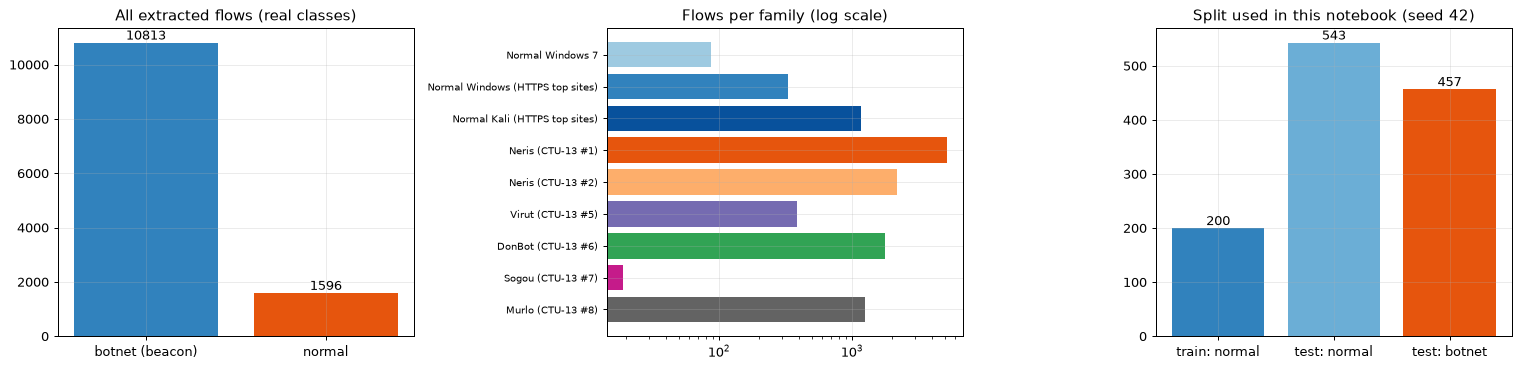

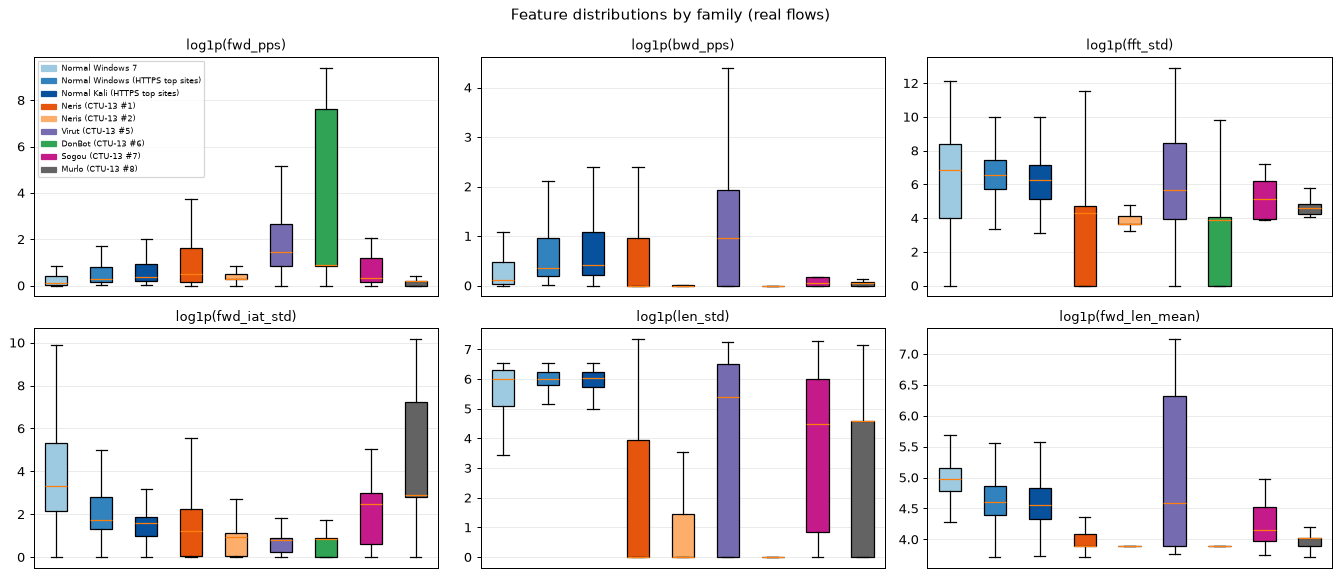

In [8]:
FAMILY_ORDER = ["Normal Windows 7", "Normal Windows (HTTPS top sites)", "Normal Kali (HTTPS top sites)",
                "Neris (CTU-13 #1)", "Neris (CTU-13 #2)", "Virut (CTU-13 #5)", "DonBot (CTU-13 #6)",
                "Sogou (CTU-13 #7)", "Murlo (CTU-13 #8)"]
FAMILY_COLOR = dict(zip(FAMILY_ORDER, ["#9ecae1", "#3182bd", "#08519c", "#e6550d", "#fdae6b", "#756bb1", "#31a354", "#c51b8a", "#636363"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cnt = FLOWS.label.map({0: "normal", 1: "botnet (beacon)"}).value_counts()
ax[0].bar(cnt.index, cnt.values, color=["#3182bd", "#e6550d"]); ax[0].set_title("All extracted flows (real classes)")
for i, v in enumerate(cnt.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
fam = FLOWS.family.value_counts().reindex(FAMILY_ORDER)
ax[1].barh(range(len(fam)), fam.values, color=[FAMILY_COLOR[f] for f in fam.index]); ax[1].set_yticks(range(len(fam)))
ax[1].set_yticklabels(fam.index, fontsize=8); ax[1].invert_yaxis(); ax[1].set_xscale("log"); ax[1].set_title("Flows per family (log scale)")
trc = pd.Series({"train: normal": len(ds42.train), "test: normal": int((ds42.y_test == 0).sum()), "test: botnet": int(ds42.y_test.sum())})
ax[2].bar(trc.index, trc.values, color=["#3182bd", "#6baed6", "#e6550d"]); ax[2].set_title("Split used in this notebook (seed 42)")
for i, v in enumerate(trc.values): ax[2].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for a, f in zip(axes.ravel(), FEATURES):
    data = [np.log1p(FLOWS.loc[FLOWS.family == fm, f].values) for fm in FAMILY_ORDER]
    bp = a.boxplot(data, patch_artist=True, showfliers=False)
    for patch, fm in zip(bp["boxes"], FAMILY_ORDER): patch.set_facecolor(FAMILY_COLOR[fm])
    a.set_title(f"log1p({f})", fontsize=10); a.set_xticks([])
axes[0, 0].legend([plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLOR[f]) for f in FAMILY_ORDER], FAMILY_ORDER, fontsize=6, loc="upper left")
plt.suptitle("Feature distributions by family (real flows)"); plt.tight_layout(); plt.show()

### Two-dimensional scatter plots of the real flows coloured by ground-truth label

Left: PCA coordinates (PCA fitted on the training flows only). Middle: the same coordinates scaled to [0, pi], the range used by the angle encodings. Right: two of the six angles that are actually fed to the circuits (one angle per qubit). Black crosses are the 200 training flows (normal only); coloured points are the test flows. A second figure shows the label colouring (normal / botnet) on the first four angles.

PCA explained variance ratio (fitted on training flows): [0.461 0.263]


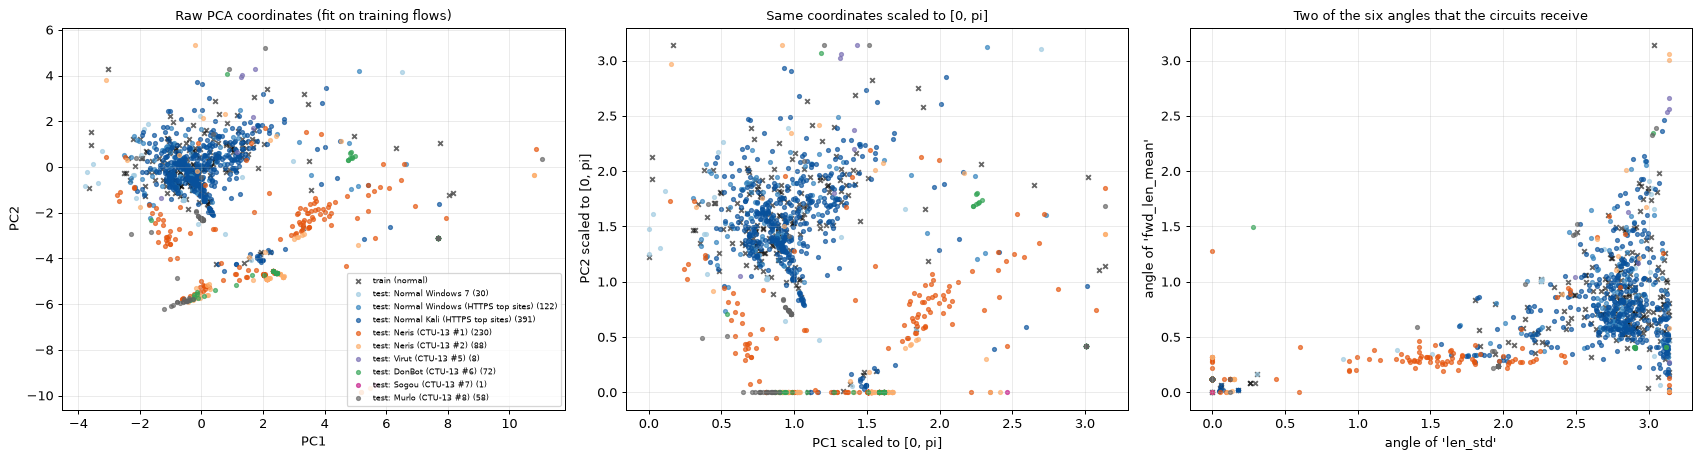

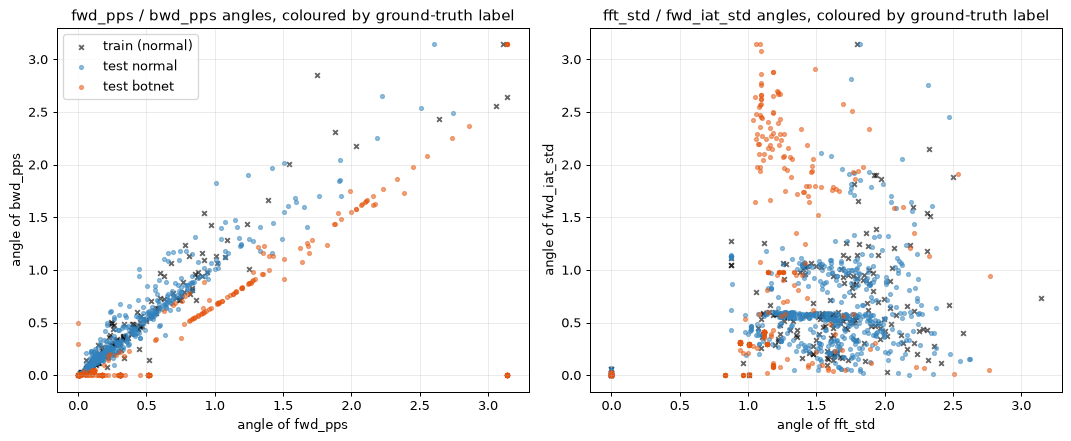

In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# PCA fitted on the training flows only (log1p + standardisation fitted on the training flows as well)
z_scaler = StandardScaler().fit(np.log1p(ds42.train[FEATURES].values))
pca2 = PCA(n_components=2, random_state=SEED).fit(z_scaler.transform(np.log1p(ds42.train[FEATURES].values)))
P_tr = pca2.transform(z_scaler.transform(np.log1p(ds42.train[FEATURES].values)))
P_te = pca2.transform(z_scaler.transform(np.log1p(ds42.test[FEATURES].values)))
ang_scaler = MinMaxScaler((0, np.pi)).fit(P_tr)                       # PCA coordinates -> [0, pi] (fitted on training flows)
A_tr, A_te = ang_scaler.transform(P_tr), np.clip(ang_scaler.transform(P_te), 0, np.pi)
print("PCA explained variance ratio (fitted on training flows):", pca2.explained_variance_ratio_.round(3))


def scatter_by_family(ax, tr, te, xl, yl, title):
    ax.scatter(tr[:, 0], tr[:, 1], s=14, c="k", marker="x", alpha=0.6, label="train (normal)")
    for fm in FAMILY_ORDER:
        m = (ds42.test.family == fm).values
        if m.any():
            ax.scatter(te[m, 0], te[m, 1], s=10, alpha=0.65, color=FAMILY_COLOR[fm], label=f"test: {fm} ({m.sum()})")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title, fontsize=10)


fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
scatter_by_family(ax[0], P_tr, P_te, "PC1", "PC2", "Raw PCA coordinates (fit on training flows)")
scatter_by_family(ax[1], A_tr, A_te, "PC1 scaled to [0, pi]", "PC2 scaled to [0, pi]", "Same coordinates scaled to [0, pi]")
scatter_by_family(ax[2], ds42.X_train[:, [4, 5]], ds42.X_test[:, [4, 5]], "angle of 'len_std'", "angle of 'fwd_len_mean'",
                  "Two of the six angles that the circuits receive")
ax[0].legend(fontsize=6.5, loc="best"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, cols, names in ((ax[0], [0, 1], "fwd_pps / bwd_pps"), (ax[1], [2, 3], "fft_std / fwd_iat_std")):
    a.scatter(ds42.X_train[:, cols[0]], ds42.X_train[:, cols[1]], s=14, c="k", marker="x", alpha=0.6, label="train (normal)")
    for lab, col, nm in ((0, "#3182bd", "test normal"), (1, "#e6550d", "test botnet")):
        m = ds42.y_test == lab
        a.scatter(ds42.X_test[m, cols[0]], ds42.X_test[m, cols[1]], s=10, alpha=0.5, color=col, label=nm)
    a.set_xlabel(f"angle of {FEATURES[cols[0]]}"); a.set_ylabel(f"angle of {FEATURES[cols[1]]}"); a.set_title(names + " angles, coloured by ground-truth label")
ax[0].legend(); plt.tight_layout(); plt.show()

## 3. The four quantum encodings and their kernels

Each flow becomes a quantum state `|phi(x)>` of 6 qubits (7 for the Hamiltonian map): one angle per feature. The notebook contains two implementations of the same four circuits:

- a **Qiskit circuit** per encoding (`feature_map_circuit`, drawn in the circuit section further down), executed with `FidelityStatevectorKernel` or `Statevector` + `partial_trace`;
- a **vectorised exact statevector simulator** in NumPy that applies the gates to a whole batch of flows at once. The hyper-parameter search evaluates thousands of kernels, which is only practical with this fast path.

The next cells define the simulator and then **assert that both agree** to machine precision for every encoding and every depth (1-5 layers) before any result is used. The fidelity kernel is `|<phi(a)|phi(b)>|^2`; the projected kernel uses the single-qubit reduced density matrices, which for qubits are Bloch vectors, so that `sum_k ||rho_k(a) - rho_k(b)||_F^2 = 1/2 * |r_a - r_b|^2`.

In [10]:
from scipy.linalg import eigh
from sklearn.svm import OneClassSVM
from sklearn.metrics.pairwise import rbf_kernel

ENCODINGS = ["Z", "IQP", "CNOT", "Hamiltonian"]
N_FEAT = len(FEATURES)                       # one feature per qubit; the Hamiltonian map uses N_FEAT + 1 qubits
HAM_T = 1.0                                  # CHOICE: total evolution time t of the Hamiltonian map (not given in the paper)
_rs = np.random.default_rng(2026)            # CHOICE: fixed 'Haar-random' single-qubit initial states |psi_j>
HAAR_THETA = np.arccos(1 - 2 * _rs.random(N_FEAT + 1))
HAAR_PHI = 2 * np.pi * _rs.random(N_FEAT + 1)


def n_qubits(enc):
    return N_FEAT + 1 if enc == "Hamiltonian" else N_FEAT


# ---------------------------------------------------------------- vectorised exact statevector simulator
# State tensor: shape (B, 2, ..., 2); axis 1+q is qubit q. All gates are applied to a whole batch of data points at once.
def _apply_1q(psi, U, q):
    return np.moveaxis(np.tensordot(U, psi, axes=([1], [q + 1])), 0, q + 1)


def _apply_diag_1q(psi, d, q):               # d: (B, 2) per-sample diagonal
    shape = [d.shape[0]] + [1] * (psi.ndim - 1); shape[q + 1] = 2
    return psi * d.reshape(shape)


def _apply_cnot(psi, c, t):
    sl = [slice(None)] * psi.ndim; sl[c + 1] = 1
    sub = psi[tuple(sl)]
    ta = t + 1 if t < c else t                # the control axis disappeared from `sub`
    out = psi.copy(); out[tuple(sl)] = np.flip(sub, axis=ta)
    return out


_H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)


def simulate(enc, layers, X):
    """Exact output states |phi(x)> of the four encodings of the paper (Appendix A), batch over rows of X."""
    X = np.atleast_2d(X); B, n = X.shape
    nq = n_qubits(enc)
    psi = np.zeros((B,) + (2,) * nq, dtype=complex)
    if enc == "Hamiltonian":                  # product of fixed single-qubit states |psi_j> = cos(th/2)|0> + e^{i phi} sin(th/2)|1>
        vecs = np.stack([np.cos(HAAR_THETA[:nq] / 2), np.exp(1j * HAAR_PHI[:nq]) * np.sin(HAAR_THETA[:nq] / 2)], 1)
        full = vecs[0]
        for q in range(1, nq):
            full = np.multiply.outer(full, vecs[q])
        psi[:] = full
    else:
        psi[(slice(None),) + (0,) * nq] = 1.0
    rz = lambda x: np.stack([np.exp(-0.5j * x), np.exp(0.5j * x)], 1)       # RZ(x) = exp(-i x Z / 2)
    if enc == "Z":
        for _ in range(layers):
            for q in range(n):
                psi = _apply_diag_1q(_apply_1q(psi, _H, q), rz(X[:, q]), q)
    elif enc == "IQP":
        idx = np.indices((2,) * nq).reshape(nq, -1).T
        zs = 1 - 2 * idx                       # eigenvalues of Z_j on the computational basis
        pairs = [(j, k) for j in range(nq) for k in range(j + 1, nq)]
        zz = np.stack([zs[:, j] * zs[:, k] for j, k in pairs], 1)
        xx = np.stack([X[:, j] * X[:, k] for j, k in pairs], 1)
        phase = np.exp(-0.5j * (X @ zs.T + xx @ zz.T)).reshape((B,) + (2,) * nq)   # U_Z(x), Eq. (A3), factor -i/2
        for _ in range(layers):
            for q in range(nq):
                psi = _apply_1q(psi, _H, q)
            psi = psi * phase
    elif enc == "CNOT":
        for _ in range(layers):
            for q in range(n):
                psi = _apply_diag_1q(_apply_1q(psi, _H, q), rz(X[:, q]), q)
            for q in range(n - 1):
                psi = _apply_cnot(psi, q, q + 1)
    elif enc == "Hamiltonian":
        T = layers                             # CHOICE: number of Trotter steps T = number of layers
        for _ in range(T):
            for j in range(n):
                th = (HAM_T / T) * X[:, j]
                th = th.reshape([B] + [1] * nq)
                # exp(-i th (XX+YY+ZZ)) = exp(i th) (cos 2th * I - i sin 2th * SWAP) because XX+YY+ZZ = 2 SWAP - I
                psi = np.exp(1j * th) * (np.cos(2 * th) * psi - 1j * np.sin(2 * th) * np.swapaxes(psi, j + 1, j + 2))
    else:
        raise ValueError(enc)
    return psi


def flat(psi):
    return psi.reshape(psi.shape[0], -1)


def bloch(psi):
    """Single-qubit reduced density matrices rho_k(x) as Bloch vectors (B, 3 * nq)."""
    B, nq = psi.shape[0], psi.ndim - 1
    out = []
    for q in range(nq):
        M = np.moveaxis(psi, q + 1, 1).reshape(B, 2, -1)
        rho = np.einsum("bar,bcr->bac", M, M.conj())
        out += [2 * rho[:, 0, 1].real, -2 * rho[:, 0, 1].imag, (rho[:, 0, 0] - rho[:, 1, 1]).real]
    return np.stack(out, 1)


def fidelity_gram(Sa, Sb):                    # |<phi(a)|phi(b)>|^2, Eq. (1)
    return np.abs(Sa.conj() @ Sb.T) ** 2


def sqdist(Ra, Rb):                           # sum_k ||rho_k(a) - rho_k(b)||_F^2 = 0.5 * |r_a - r_b|^2 over all Bloch vectors
    d = (Ra ** 2).sum(1)[:, None] + (Rb ** 2).sum(1)[None, :] - 2 * Ra @ Rb.T
    return 0.5 * np.maximum(d, 0)


def pqk_gram(D, gamma):                       # Eq. (2)
    return np.exp(-gamma * D)


# ---------------------------------------------------------------- objectives
def npd_score(s_val, s_gen, eps=1e-12):
    """Normalised pseudo discrepancy (Dai & Fan, ICLR 2025) of two anomaly-score vectors."""
    return float((s_gen.mean() - s_val.mean()) ** 2 / (2 * (s_gen.var() + s_val.var()) + eps))


_KC_CACHE = {}


def _inv_kc(KC, jitter):
    key = (KC.shape, float(KC.sum()), float(np.trace(KC @ KC)), jitter)
    if key not in _KC_CACHE:
        N = len(KC); KCn = KC * N / np.trace(KC)
        wc, Vc = np.linalg.eigh((KCn + KCn.T) / 2)
        _KC_CACHE[key] = (Vc / (np.clip(wc, 0, None) + jitter)) @ Vc.T        # CHOICE: jitter regularises K_C^{-1}
        if len(_KC_CACHE) > 8: _KC_CACHE.pop(next(iter(_KC_CACHE)))
    return _KC_CACHE[key]


def geometric_difference(KQ, KC, jitter=1e-8):
    """g_{C->Q} = sqrt(|| sqrt(K_Q) K_C^{-1} sqrt(K_Q) ||_inf), both kernels normalised to Tr = N (Eq. 3)."""
    N = len(KQ)
    KQ = KQ * N / np.trace(KQ)
    wq, Vq = np.linalg.eigh((KQ + KQ.T) / 2); sq = (Vq * np.sqrt(np.clip(wq, 0, None))) @ Vq.T
    M = sq @ _inv_kc(KC, jitter) @ sq
    return float(np.sqrt(max(np.linalg.eigvalsh((M + M.T) / 2)[-1], 0)))

def pareto_mask(P):
    """Non-dominated rows of P (n, 2), both objectives to be maximised."""
    P = np.asarray(P, float); keep = np.ones(len(P), bool)
    for i in range(len(P)):
        dom = np.all(P >= P[i], 1) & np.any(P > P[i], 1)
        if dom.any():
            keep[i] = False
    return keep


def knee_point(P):
    """Index (into P) of the front point closest to the utopia point (1, 1) after rescaling both objectives to [0, 1] over the front."""
    P = np.asarray(P, float); idx = np.where(pareto_mask(P))[0]
    F = P[idx]; lo, hi = F.min(0), F.max(0)
    Z = (F - lo) / np.where(hi - lo > 0, hi - lo, 1)
    return int(idx[np.argmin(np.hypot(1 - Z[:, 0], 1 - Z[:, 1]))])


# ---------------------------------------------------------------- benchmark object: caches kernels for one data split
class Bench:
    def __init__(self, ds):
        self.ds = ds
        self.XA = np.vstack([ds.X_train, ds.X_gen])           # 200 training + m generated points
        self.nT = len(ds.X_train)
        self._cache = {}

    def base(self, kind, enc, layers):
        key = (kind, enc, layers)
        if key not in self._cache:
            psi = simulate(enc, layers, self.XA)
            self._cache[key] = fidelity_gram(flat(psi), flat(psi)) if kind == "fid" else sqdist(bloch(psi), bloch(psi))
        return self._cache[key]

    def gram(self, cfg):
        kind = cfg["kind"]
        if kind == "rbf":
            return rbf_kernel(self.XA, self.XA, gamma=cfg["gamma"])
        B = self.base(kind, cfg["enc"], cfg["layers"])
        return B if kind == "fid" else pqk_gram(B, cfg["gamma"])

    def npd(self, cfg, K=None):
        K = self.gram(cfg) if K is None else K
        ds = self.ds
        try:
            svm = OneClassSVM(kernel="precomputed", nu=cfg["nu"]).fit(K[np.ix_(ds.idx_trn, ds.idx_trn)])
        except ValueError:                        # degenerate kernel (e.g. K -> identity): no usable model, NPD = 0
            return 0.0
        s_val = -svm.decision_function(K[np.ix_(ds.idx_val, ds.idx_trn)])
        s_gen = -svm.decision_function(K[self.nT:, :][:, ds.idx_trn])
        return npd_score(s_val, s_gen)

    def gd(self, cfg, KC, K=None):
        K = self.gram(cfg) if K is None else K
        return geometric_difference(K[:self.nT, :self.nT], KC)

In [11]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, partial_trace
from qiskit_machine_learning.kernels import FidelityStatevectorKernel


def feature_map_circuit(enc, layers):
    """The data-encoding unitary U(x) of Appendix A as a Qiskit circuit (this is the circuit that is executed)."""
    n, nq = N_FEAT, n_qubits(enc)
    x = ParameterVector("x", n)
    qc = QuantumCircuit(nq, name=f"{enc}_L{layers}")
    if enc == "Z":                                           # [ (x) RZ(x_j) H^n ]^L : separable
        for _ in range(layers):
            for q in range(n): qc.h(q)
            for q in range(n): qc.rz(x[q], q)
    elif enc == "IQP":                                       # [ U_Z(x) H^n ]^L, U_Z = exp(-i/2 (sum x_j Z_j + sum x_j x_k Z_j Z_k))
        for _ in range(layers):
            for q in range(n): qc.h(q)
            for q in range(n): qc.rz(x[q], q)
            for j in range(n):
                for k in range(j + 1, n): qc.rzz(x[j] * x[k], j, k)
    elif enc == "CNOT":                                      # [ CNOT ladder . RZ(x_j) . H^n ]^L
        for _ in range(layers):
            for q in range(n): qc.h(q)
            for q in range(n): qc.rz(x[q], q)
            for q in range(n - 1): qc.cx(q, q + 1)
    elif enc == "Hamiltonian":                               # Trotterised exp(-i t x_j (XX+YY+ZZ)), n+1 qubits, fixed initial states
        for q in range(nq):
            qc.ry(float(HAAR_THETA[q]), q); qc.rz(float(HAAR_PHI[q]), q)    # cos(th/2)|0> + e^{i phi} sin(th/2)|1>
        for _ in range(layers):
            for j in range(n):
                a = 2 * (HAM_T / layers) * x[j]              # exp(-i th P P) = R_PP(2 th)
                qc.rxx(a, j, j + 1); qc.ryy(a, j, j + 1); qc.rzz(a, j, j + 1)
    else:
        raise ValueError(enc)
    return qc


def circuit_facts(qc):
    return dict(qubits=qc.num_qubits, depth=qc.depth(), size=qc.size(), data_params=qc.num_parameters,
                trainable_params=0, two_qubit_gates=sum(1 for i in qc.data if i.operation.num_qubits == 2))


def qiskit_states(qc, X):
    return [Statevector(qc.assign_parameters(dict(zip(qc.parameters, row)))) for row in np.atleast_2d(X)]


def qiskit_reduced(states):
    """Single-qubit reduced density matrices of every state, stacked as real vectors (via qiskit partial_trace)."""
    out = []
    for sv in states:
        nq = sv.num_qubits; parts = []
        for q in range(nq):
            rho = partial_trace(sv, [k for k in range(nq) if k != q]).data
            parts += [rho.real.ravel(), rho.imag.ravel()]
        out.append(np.concatenate(parts))
    return np.array(out)


def qiskit_sqdist(Ra, Rb):                                    # sum_k ||rho_k(a) - rho_k(b)||_F^2 from the stacked real vectors
    d = (Ra ** 2).sum(1)[:, None] + (Rb ** 2).sum(1)[None, :] - 2 * Ra @ Rb.T
    return np.maximum(d, 0)


def qiskit_kernels(cfg, Xa, Xb):
    """Kernel matrix between rows of Xa and Xb computed with Qiskit objects only
    (FidelityStatevectorKernel for the fidelity kernel, Statevector + partial_trace for the projected kernel)."""
    qc = feature_map_circuit(cfg["enc"], cfg["layers"])
    if cfg["kind"] == "fid":
        return FidelityStatevectorKernel(feature_map=qc).evaluate(Xa, Xb)
    Ra, Rb = qiskit_reduced(qiskit_states(qc, Xa)), qiskit_reduced(qiskit_states(qc, Xb))
    return pqk_gram(qiskit_sqdist(Ra, Rb), cfg["gamma"])

In [12]:
# Equivalence check: vectorised simulator vs Qiskit (states, fidelity kernel, projected-kernel distances) for all 4 encodings x 1..5 layers
_X = Dataset(SEED).X_train[:6]
_worst = 0.0
_rows = []
for enc in ENCODINGS:
    for L in range(1, 6):
        qc = feature_map_circuit(enc, L)
        psi = simulate(enc, L, _X)
        sv = qiskit_states(qc, _X)
        overlap = []
        for i, s in enumerate(sv):
            a = s.data.reshape((2,) * qc.num_qubits).transpose(tuple(range(qc.num_qubits))[::-1]).ravel()     # Qiskit is little-endian
            overlap.append(abs(np.vdot(a, psi[i].ravel())))
        dK = np.abs(FidelityStatevectorKernel(feature_map=qc).evaluate(_X, _X) - fidelity_gram(flat(psi), flat(psi))).max()
        Rq = qiskit_reduced(sv)
        dD = np.abs(qiskit_sqdist(Rq, Rq) - sqdist(bloch(psi), bloch(psi))).max()
        err = max(1 - min(overlap), dK, dD); _worst = max(_worst, err)
        _rows.append((enc, L, 1 - min(overlap), dK, dD))
assert _worst < 1e-10, _worst
print(pd.DataFrame(_rows, columns=["encoding", "layers", "1 - min state overlap", "max |K_fid diff|", "max |D_pqk diff|"]).to_string(index=False, float_format=lambda v: f"{v:.1e}"))
print(f"\nAll 20 circuits agree with the vectorised simulator (worst deviation {_worst:.1e}).")

   encoding  layers  1 - min state overlap  max |K_fid diff|  max |D_pqk diff|
          Z       1                1.3e-15           3.3e-15           7.1e-15
          Z       2                2.9e-15           5.8e-15           5.3e-15
          Z       3                4.1e-15           8.2e-15           8.0e-15
          Z       4                5.6e-15           1.1e-14           3.6e-15
          Z       5                7.0e-15           1.4e-14           6.2e-15
        IQP       1                1.1e-15           2.4e-15           2.2e-15
        IQP       2                2.3e-15           4.2e-15           4.4e-15
        IQP       3                3.6e-15           6.9e-15           6.0e-15
        IQP       4                4.9e-15           9.3e-15           8.0e-15
        IQP       5                6.0e-15           1.1e-14           5.8e-15
       CNOT       1                1.3e-15           3.3e-15           2.4e-15
       CNOT       2                2.7e-15          

## 4. The two label-free objectives and the Pareto knee

- `npd_score` implements the NPD from the anomaly scores of the validation and generated sets.
- `geometric_difference` implements `g_C->Q` of Eq. (3) after normalising both Gram matrices to trace N. A kernel identical to the reference gives `g = 1`; a kernel that is the identity matrix gives `g^2 = ||K_C^-1|| = 1/lambda_min(K_C)` (this is the mechanism the paper uses to explain its very large GD values for the projected kernel at large `gamma`).
- `pareto_mask` marks the non-dominated points and `knee_point` returns the front point closest to (1, 1) after rescaling both objectives to [0, 1].

The optimisers (`NSGA2`, `TPE`) are tested next on toy problems with known answers. The inputs of these tests are synthetic on purpose: they test the code, they are not data of the study.

In [13]:
# Label-free hyper-parameter search. Optuna is the paper's tool (NSGA-II for the joint objective, TPE for single objectives).
# CHOICE: Optuna is not installed in the local test environment, so compact re-implementations of NSGA-II and of an
# independent (univariate) TPE are used; the search space is Table I of the paper.
SPACES = {
    "fid": [("enc", "cat", ENCODINGS), ("layers", "cat", [1, 2, 3, 4, 5]), ("nu", "float", (0.01, 1.0))],
    "pqk": [("enc", "cat", ENCODINGS), ("layers", "cat", [1, 2, 3, 4, 5]), ("nu", "float", (0.01, 1.0)),
            ("gamma", "log", (1e-4, 10.0))],
    "rbf": [("gamma", "log", (1e-3, 100.0)), ("nu", "float", (0.01, 1.0))],
}


def _sample_prior(space, rng):
    p = {}
    for name, typ, dom in space:
        p[name] = dom[rng.integers(len(dom))] if typ == "cat" else (
            rng.uniform(*dom) if typ == "float" else float(np.exp(rng.uniform(np.log(dom[0]), np.log(dom[1])))))
    return p


class TPE:
    """Minimal univariate Tree-structured Parzen Estimator (maximisation)."""
    def __init__(self, space, rng, n_startup=10, top=0.25, n_cand=24):
        self.space, self.rng, self.n_startup, self.top, self.n_cand = space, rng, n_startup, top, n_cand

    def _fit(self, vals, lo, hi):
        v = np.sort(np.asarray(vals, float)); n = len(v)
        pts = np.concatenate([v, [(lo + hi) / 2]])            # prior component
        srt = np.sort(pts)
        left = np.diff(np.concatenate([[lo], srt])); right = np.diff(np.concatenate([srt, [hi]]))
        sig_sorted = np.maximum(left, right)
        order = np.argsort(np.argsort(pts, kind="stable"), kind="stable")
        sig = np.clip(sig_sorted[order], (hi - lo) / min(100, n + 2), hi - lo)
        sig[-1] = hi - lo
        return pts, sig

    @staticmethod
    def _pdf(x, pts, sig):
        z = (x[:, None] - pts[None, :]) / sig[None, :]
        return (np.exp(-0.5 * z ** 2) / (sig[None, :] * np.sqrt(2 * np.pi))).mean(1) + 1e-12

    def suggest(self, hist):
        if len(hist) < self.n_startup:
            return _sample_prior(self.space, self.rng)
        vals = np.array([h[1] for h in hist]); k = max(1, int(np.ceil(self.top * len(hist))))
        order = np.argsort(-vals); good = [hist[i][0] for i in order[:k]]; bad = [hist[i][0] for i in order[k:]] or good
        logscore = np.zeros(self.n_cand); cands = {name: None for name, _, _ in self.space}
        for name, typ, dom in self.space:
            if typ == "cat":
                cnt = lambda grp: np.array([sum(g[name] == d for g in grp) + 1.0 for d in dom]) / (len(grp) + len(dom))
                pg, pb = cnt(good), cnt(bad)
                pick = self.rng.choice(len(dom), size=self.n_cand, p=pg)
                cands[name] = [dom[i] for i in pick]
                logscore += np.log(pg[pick]) - np.log(pb[pick])
            else:
                tr = np.log if typ == "log" else (lambda a: np.asarray(a, float))
                inv = np.exp if typ == "log" else (lambda a: a)
                lo, hi = tr(dom[0]), tr(dom[1])
                pts_g, sg_g = self._fit([tr(g[name]) for g in good], lo, hi)
                pts_b, sg_b = self._fit([tr(g[name]) for g in bad], lo, hi)
                comp = self.rng.integers(len(pts_g), size=self.n_cand)
                x = np.clip(self.rng.normal(pts_g[comp], sg_g[comp]), lo, hi)
                cands[name] = [float(inv(v)) for v in x]
                logscore += np.log(self._pdf(x, pts_g, sg_g)) - np.log(self._pdf(x, pts_b, sg_b))
        j = int(np.argmax(logscore))
        return {name: cands[name][j] for name, _, _ in self.space}


def nondominated_sort(P):
    P = np.asarray(P, float); n = len(P); rank = np.zeros(n, int); remaining = np.arange(n); r = 0
    while len(remaining):
        m = pareto_mask(P[remaining]); rank[remaining[m]] = r; remaining = remaining[~m]; r += 1
    return rank


def crowding(P):
    P = np.asarray(P, float); n = len(P); d = np.zeros(n)
    for m in range(P.shape[1]):
        o = np.argsort(P[:, m]); d[o[0]] = d[o[-1]] = np.inf
        span = P[o[-1], m] - P[o[0], m]
        if span > 0 and n > 2:
            d[o[1:-1]] += (P[o[2:], m] - P[o[:-2], m]) / span
    return d


class NSGA2:
    """Minimal NSGA-II (maximisation of two objectives), population `pop`, tournament selection,
    uniform crossover and per-gene mutation."""
    def __init__(self, space, rng, pop=20, p_cross=0.9):
        self.space, self.rng, self.pop, self.p_cross = space, rng, pop, p_cross
        self.parents = []                                   # list of (params, objective vector)
        self.offspring_queue = []

    def _mutate(self, p):
        q = dict(p)
        for name, typ, dom in self.space:
            if self.rng.random() < 1.0 / len(self.space):
                if typ == "cat":
                    q[name] = dom[self.rng.integers(len(dom))]
                elif typ == "float":
                    q[name] = float(np.clip(q[name] + self.rng.normal(0, 0.15 * (dom[1] - dom[0])), *dom))
                else:
                    lo, hi = np.log(dom[0]), np.log(dom[1])
                    q[name] = float(np.exp(np.clip(np.log(q[name]) + self.rng.normal(0, 0.15 * (hi - lo)), lo, hi)))
        return q

    def _tournament(self):
        i, j = self.rng.integers(len(self.parents), size=2)
        a, b = self.parents[i], self.parents[j]
        return a if (a[2], -a[3]) <= (b[2], -b[3]) else b

    def _new_generation(self):
        kids = []
        while len(kids) < self.pop:
            p1, p2 = self._tournament()[0], self._tournament()[0]
            child = {n: (p1[n] if self.rng.random() < 0.5 else p2[n]) for n, _, _ in self.space} \
                if self.rng.random() < self.p_cross else dict(p1)
            kids.append(self._mutate(child))
        return kids

    def ask(self):
        if not self.offspring_queue:
            self.offspring_queue = [_sample_prior(self.space, self.rng) for _ in range(self.pop)] if not self.parents \
                else self._new_generation()
        return self.offspring_queue.pop(0)

    def tell_generation(self, evaluated):                    # evaluated: list of (params, objectives)
        pool = [(p, o) for p, o in evaluated] + [(p, o) for p, o, _, _ in self.parents]
        P = np.array([o for _, o in pool]); rank = nondominated_sort(P); crowd = np.zeros(len(pool))
        for r in np.unique(rank):
            crowd[rank == r] = crowding(P[rank == r])
        order = sorted(range(len(pool)), key=lambda i: (rank[i], -crowd[i]))[:self.pop]
        self.parents = [(pool[i][0], pool[i][1], int(rank[i]), float(crowd[i])) for i in order]


def run_search(bench, kind, objective, n_trials, rng, KC, nu_ref, pop=20, verbose=False):
    """objective in {'npd', 'gd', 'joint'}. Returns a list of trial dicts (params + npd + gd).
    The search sees only label-free quantities (NPD from generated data, GD from the training Gram matrices)."""
    space = SPACES[kind]
    if objective == "gd":                                    # GD does not depend on nu
        space = [s for s in space if s[0] != "nu"]
    trials, hist = [], []
    tpe = TPE(space, rng) if objective != "joint" else None
    ga = NSGA2(space, rng, pop=pop) if objective == "joint" else None
    batch = []
    for t in range(n_trials):
        params = tpe.suggest(hist) if tpe else ga.ask()
        cfg = dict(kind=kind, **params)
        if "nu" not in cfg:
            cfg["nu"] = nu_ref
        K = bench.gram(cfg)
        npd_v = bench.npd(cfg, K); gd_v = bench.gd(cfg, KC, K)
        trials.append(dict(cfg, npd=npd_v, gd=gd_v, trial=t))
        if objective == "npd":
            hist.append((params, npd_v))
        elif objective == "gd":
            hist.append((params, gd_v))
        else:
            batch.append((params, (npd_v, gd_v)))
            if len(batch) == pop:
                ga.tell_generation(batch); batch = []
        if verbose and t % 20 == 0:
            print(f"    trial {t:3d}  NPD={npd_v:.3f}  GD={gd_v:.2f}  {params}")
    return trials


def tune_nu_by_npd(bench, cfg, grid=np.linspace(0.02, 1.0, 50)):
    """Label-free choice of nu for a kernel selected by GD (GD itself does not involve nu)."""
    K = bench.gram(cfg)
    vals = [bench.npd(dict(cfg, nu=float(nu)), K) for nu in grid]
    return float(grid[int(np.argmax(vals))]), float(max(vals))


def test_decisions(bench, cfg, Ktest_train):
    """Train OCSVM on the 200 training flows with the Gram matrix and score the test flows."""
    K = bench.gram(cfg)[:bench.nT, :bench.nT]
    try:
        svm = OneClassSVM(kernel="precomputed", nu=cfg["nu"]).fit(K)
    except ValueError:                        # degenerate kernel (K -> identity): no model; constant scores = chance-level AUC
        return np.zeros(len(Ktest_train))
    return svm.decision_function(Ktest_train)

In [14]:
def test_gram(bench, cfg):
    """Kernel between the test flows and the 200 training flows (fast vectorised path)."""
    ds = bench.ds
    if cfg["kind"] == "rbf":
        return rbf_kernel(ds.X_test, ds.X_train, gamma=cfg["gamma"])
    cache = bench.__dict__.setdefault("_tcache", {})
    key = (cfg["kind"], cfg["enc"], cfg["layers"])
    if key not in cache:
        pt, ptr = simulate(cfg["enc"], cfg["layers"], ds.X_test), simulate(cfg["enc"], cfg["layers"], ds.X_train)
        cache[key] = fidelity_gram(flat(pt), flat(ptr)) if cfg["kind"] == "fid" else sqdist(bloch(pt), bloch(ptr))
    B = cache[key]
    return B if cfg["kind"] == "fid" else pqk_gram(B, cfg["gamma"])


def score_config(bench, cfg, Kt=None):
    """Test metrics of a configuration, flow level and per source-destination pair."""
    Kt = test_gram(bench, cfg) if Kt is None else Kt
    dec = test_decisions(bench, cfg, Kt)
    return evaluate_scores(dec, bench.ds.y_test, bench.ds.pair_test), dec


def tune_classical(bench, n_trials, rng):
    """Tuned classical reference: RBF one-class SVM, (gamma, nu) maximising the NPD (the paper's protocol)."""
    tpe, hist, best = TPE(SPACES["rbf"], rng), [], None
    for t in range(n_trials):
        p = tpe.suggest(hist); cfg = dict(kind="rbf", **p)
        v = bench.npd(cfg); hist.append((p, v))
        if best is None or v > best[1]:
            best = (cfg, v)
    return best

In [15]:
# Unit tests of the three objective functions (synthetic toy inputs, used only to test the code - no data is faked)
rs = np.random.default_rng(0)
a = rs.normal(size=200)
assert npd_score(a, a) == 0.0 and npd_score(a, a + 3.0) > 1.0, "NPD must vanish for identical scores and grow with the shift"
print("NPD: identical scores ->", npd_score(a, a), "| shifted by 3 sigma ->", round(npd_score(a, a + 3.0), 3))

Xr = rs.uniform(0, np.pi, size=(60, 6)); Kr = rbf_kernel(Xr, gamma=1.0)
g_same = geometric_difference(Kr, Kr)
lam_min = np.linalg.eigvalsh(Kr).min() + 1e-8
g_id = geometric_difference(np.eye(60), Kr)
assert abs(g_same - 1.0) < 1e-3, g_same
assert abs(g_id ** 2 - 1.0 / lam_min) / (1.0 / lam_min) < 1e-3, (g_id ** 2, 1 / lam_min)
print(f"GD: g(K,K) = {g_same:.4f} (must be 1);  g(I,K)^2 = {g_id ** 2:.3f}  vs  1/lambda_min(K) = {1 / lam_min:.3f}  (paper, Sec. IV B)")

P = np.array([[0.0, 1.0], [0.5, 0.8], [1.0, 0.1], [0.4, 0.4]])        # columns: NPD, GD (both maximised)
assert pareto_mask(P).tolist() == [True, True, True, False]
assert knee_point(P) == 1
print("Pareto mask:", pareto_mask(P).tolist(), "| knee index (closest to utopia (1,1) after rescaling):", knee_point(P))

# the fast metric implementations agree with scikit-learn
yy, dd = rs.integers(0, 2, 300), np.round(rs.normal(size=300), 1)           # rounding creates ties
mm = _metrics(dd, yy)
assert abs(mm["auc"] - roc_auc_score(yy, -dd)) < 1e-12
assert abs(mm["f1_A"] - f1_score(yy, (dd < 0).astype(int), pos_label=1)) < 1e-12
assert abs(mm["f1_N"] - f1_score(yy, (dd < 0).astype(int), pos_label=0)) < 1e-12
print("fast AUC / F1 equal scikit-learn:", round(mm["auc"], 4), round(mm["f1_A"], 4), round(mm["f1_N"], 4))

# NSGA-II / TPE smoke test on a known 2-objective problem: maximise (x, 1 - x) -> every x is Pareto optimal
toy_space = [("x", "float", (0.0, 1.0))]
ga = NSGA2(toy_space, np.random.default_rng(1), pop=8)
for _ in range(3):
    batch = []
    for _ in range(8):
        p = ga.ask(); batch.append((p, (p["x"], 1 - p["x"])))
    ga.tell_generation(batch)
assert all(r == 0 for _, _, r, _ in ga.parents), "all points of a perfectly conflicting problem are non-dominated"
tpe_t = TPE([("x", "float", (0.0, 1.0))], np.random.default_rng(2)); hist = []
for _ in range(40):
    p = tpe_t.suggest(hist); hist.append((p, -(p["x"] - 0.7) ** 2))
print("TPE on f(x) = -(x-0.7)^2: best x after 40 trials =", round(max(hist, key=lambda h: h[1])[0]["x"], 3))
assert abs(max(hist, key=lambda h: h[1])[0]["x"] - 0.7) < 0.1
print("all objective / optimiser checks passed")

NPD: identical scores -> 0.0 | shifted by 3 sigma -> 2.435
GD: g(K,K) = 1.0000 (must be 1);  g(I,K)^2 = 3.673  vs  1/lambda_min(K) = 3.673  (paper, Sec. IV B)
Pareto mask: [True, True, True, False] | knee index (closest to utopia (1,1) after rescaling): 1
fast AUC / F1 equal scikit-learn: 0.5427 0.5294 0.5102


TPE on f(x) = -(x-0.7)^2: best x after 40 trials = 0.698
all objective / optimiser checks passed


## 5. Tuned classical reference, quantum kernel searches and selection

For each seed the pipeline does the following (labels are never used until the last step of each item):

1. **Classical reference.** Tune an RBF OCSVM by maximising the NPD, as in the paper. Its Gram matrix on the 200 training flows is `K_C`.
2. **Six searches.** For the fidelity and for the projected kernel: (a) maximise NPD with TPE, (b) maximise GD with TPE, (c) maximise (NPD, GD) with NSGA-II. Each trial picks the encoding, the number of layers, `nu` and (projected kernel) `gamma`, builds the Gram matrix of the 200 training and 40 generated points, and returns NPD and GD.
3. **Selection.** Best NPD, best GD (with `nu` chosen by NPD because GD does not depend on `nu`), and the Pareto knee.
4. **Evaluation on the test flows.** Only now are labels used: AUC and F1 for the selected kernels. For the main seed the selected kernels are re-evaluated with the Qiskit circuits themselves and compared with the fast path. For the figures, the test AUC of *every* explored configuration is also computed afterwards (never used for selection).

In [16]:
KINDS = ("fid", "pqk")
OBJECTIVES = ("npd", "gd", "joint")
OBJ_LABEL = {"npd": "NPD", "gd": "GD", "joint": "Pareto knee"}
CFG_KEYS = ("kind", "enc", "layers", "nu", "gamma")


def clean_cfg(row):
    cfg = {k: row[k] for k in CFG_KEYS if k in row and not (isinstance(row[k], float) and np.isnan(row[k]))}
    cfg["layers"] = int(cfg["layers"]); cfg["nu"] = float(cfg["nu"])
    if "gamma" in cfg: cfg["gamma"] = float(cfg["gamma"])
    return cfg


def select(df, objective):
    """Label-free selection rule of the paper: best NPD, best GD, or the Pareto knee point."""
    if objective == "npd": return df.loc[df.npd.idxmax()]
    if objective == "gd": return df.loc[df.gd.idxmax()]
    return df.loc[knee_point(df[["npd", "gd"]].values)]


def qiskit_final_metrics(bench, cfg):
    """Test metrics of one selected configuration computed with Qiskit objects only, and the maximal
    deviation of the Qiskit Gram matrices from the vectorised ones."""
    ds = bench.ds
    Ktr = qiskit_kernels(cfg, ds.X_train, ds.X_train); Kte = qiskit_kernels(cfg, ds.X_test, ds.X_train)
    dev = max(np.abs(Ktr - bench.gram(cfg)[:bench.nT, :bench.nT]).max(), np.abs(Kte - test_gram(bench, cfg)).max())
    svm = OneClassSVM(kernel="precomputed", nu=cfg["nu"]).fit(Ktr)
    return evaluate_scores(svm.decision_function(Kte), ds.y_test, ds.pair_test), dev


def run_pipeline(seed, use_qiskit=False, verbose=True):
    t0 = time.time()
    ds = Dataset(seed); bench = Bench(ds)
    rng = np.random.default_rng(seed)
    cfgC, npdC = tune_classical(bench, N_TRIALS_RBF, rng)                 # tuned classical reference (NPD, label-free)
    KC = bench.gram(cfgC)[:bench.nT, :bench.nT]
    mC, _ = score_config(bench, cfgC)
    res = dict(seed=seed, ds=ds, bench=bench, cfgC=cfgC, npdC=npdC, KC=KC, metricsC=mC, runs={}, selected={})
    for kind in KINDS:
        for obj in OBJECTIVES:
            n_trials = N_TRIALS_FID if kind == "fid" else N_TRIALS_PQK
            tr = pd.DataFrame(run_search(bench, kind, obj, n_trials, np.random.default_rng(seed * 100 + len(res["runs"])),
                                         KC, cfgC["nu"], pop=POP))
            # --- evaluation only (never used for selection): test AUC of every explored configuration
            aucs = []
            for _, row in tr.iterrows():
                s, _ = score_config(bench, clean_cfg(row))
                aucs.append(s["pair"]["auc"])
            tr["test_auc"] = aucs
            res["runs"][(kind, obj)] = tr
            best = select(tr, obj); cfg = clean_cfg(best)
            nu_note = ""
            if obj == "gd":                                                # GD does not involve nu: pick nu by NPD
                cfg["nu"], _ = tune_nu_by_npd(bench, cfg); nu_note = "nu re-tuned on NPD"
            Kfull = bench.gram(cfg)
            sel = dict(cfg=cfg, npd=bench.npd(cfg, Kfull), gd=bench.gd(cfg, KC, Kfull), nu_note=nu_note)
            sel["metrics"], _ = score_config(bench, cfg)
            if use_qiskit:
                sel["metrics_qiskit"], sel["qiskit_dev"] = qiskit_final_metrics(bench, cfg)
            res["selected"][(kind, obj)] = sel
    res["seconds"] = time.time() - t0
    if verbose:
        print(f"seed {seed}: classical AUC(pair)={mC['pair']['auc']:.3f}  gamma={cfgC['gamma']:.2f} nu={cfgC['nu']:.3f}   [{res['seconds']:.0f}s]")
    return res

In [17]:
t_all = time.time()
RESULTS = {}
for s in SEEDS:
    RESULTS[s] = run_pipeline(s, use_qiskit=(s == SEED))
res = RESULTS[SEED]
print(f"\nall searches finished in {(time.time() - t_all) / 60:.1f} minutes")
assert all(v["qiskit_dev"] < 1e-9 for v in res["selected"].values()), "Qiskit kernels must equal the vectorised kernels"
print("Largest deviation between Qiskit and vectorised Gram matrices of the selected kernels:", f"{max(v['qiskit_dev'] for v in res['selected'].values()):.1e}")

seed 42: classical AUC(pair)=0.897  gamma=10.45 nu=0.176   [140s]


seed 43: classical AUC(pair)=0.889  gamma=5.58 nu=0.060   [51s]


seed 44: classical AUC(pair)=0.857  gamma=7.42 nu=0.010   [47s]


seed 45: classical AUC(pair)=0.883  gamma=3.54 nu=0.010   [45s]


seed 46: classical AUC(pair)=0.863  gamma=4.14 nu=0.178   [35s]

all searches finished in 5.3 minutes
Largest deviation between Qiskit and vectorised Gram matrices of the selected kernels: 7.4e-14


In [18]:
from scipy.stats import spearmanr
KIND_NAME = {"fid": "Fidelity kernel", "pqk": "Projected kernel"}
KIND_COLOR = {"fid": "#1f77b4", "pqk": "#d62728"}
SQRT_N = np.sqrt(N_TRAIN)


def selection_table(res, metrics_key="metrics_qiskit"):
    """Tables IV/V and VI of the paper for one seed (pair-aggregated test metrics)."""
    rows = []
    for (kind, obj), s in res["selected"].items():
        m = (s.get(metrics_key) or s["metrics"])["pair"]
        c = s["cfg"]
        rows.append(dict(kernel=KIND_NAME[kind], objective={"npd": "NPD", "gd": "GD", "joint": "Pareto knee"}[obj],
                         feature_map=c["enc"], layers=c["layers"], nu=round(c["nu"], 3),
                         gamma=round(c["gamma"], 5) if "gamma" in c else "-", NPD=round(s["npd"], 3), GD=round(s["gd"], 2),
                         AUC=round(m["auc"], 3), F1_A=round(m["f1_A"], 3), F1_N=round(m["f1_N"], 3)))
    return pd.DataFrame(rows)


def fig_fronts(res):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for a, kind in zip(ax, KINDS):
        tr = res["runs"][(kind, "joint")]; P = tr[["npd", "gd"]].values; m = pareto_mask(P)
        a.scatter(tr.npd, tr.gd, s=12, color="lightgrey", label="all NSGA-II trials")
        o = np.argsort(P[m][:, 0]); a.plot(P[m][o, 0], P[m][o, 1], "o-", color=KIND_COLOR[kind], label="Pareto front")
        k = knee_point(P); a.plot(P[k, 0], P[k, 1], "*", ms=16, color="gold", mec="k", label=f"knee NPD={P[k, 0]:.2f}, GD={P[k, 1]:.2f}")
        a.axhline(SQRT_N, color="green", ls="--", label=f"sqrt(N) = {SQRT_N:.2f}")
        a.set_xlabel("NPD (higher is better)"); a.set_ylabel("geometric difference GD"); a.set_title(KIND_NAME[kind] + f" (seed {res['seed']})"); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def fig_gd_npd_vs_auc(res):
    base = res["metricsC"]["pair"]["auc"]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for kind in KINDS:
        tr = res["runs"][(kind, "gd")]; ax[0].scatter(tr.gd, tr.test_auc, s=14, color=KIND_COLOR[kind], alpha=0.7, label=KIND_NAME[kind])
        ib = tr.gd.idxmax(); ax[0].scatter(tr.gd[ib], tr.test_auc[ib], s=140, marker="*", color="gold", edgecolor="k", zorder=5)
        tr = res["runs"][(kind, "npd")]; ax[1].scatter(tr.npd, tr.test_auc, s=14, color=KIND_COLOR[kind], alpha=0.7, label=KIND_NAME[kind])
        ib = tr.npd.idxmax(); ax[1].scatter(tr.npd[ib], tr.test_auc[ib], s=140, marker="*", color="gold", edgecolor="k", zorder=5)
    ax[0].axvline(SQRT_N, color="green", ls="--", label="sqrt(N)")
    for a, xl, t in ((ax[0], "geometric difference GD", "GD vs test AUC (GD-maximisation run)"), (ax[1], "NPD", "NPD vs test AUC (NPD-maximisation run)")):
        a.axhline(base, color="orange", ls=":", label=f"tuned classical OCSVM AUC={base:.3f}")
        a.set_xlabel(xl); a.set_ylabel("test AUC (per pair)"); a.set_title(t + "  (stars = largest value)"); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def corr_table(res):
    rows = []
    for kind in KINDS:
        for obj, col in (("npd", "npd"), ("gd", "gd")):
            tr = res["runs"][(kind, obj)]
            r = spearmanr(tr[col], tr.test_auc)
            rows.append(dict(kernel=KIND_NAME[kind], run=obj.upper() + "-maximisation", n_trials=len(tr), spearman_rho=round(r.statistic, 3),
                             p_value=round(r.pvalue, 4), best_test_auc_in_run=round(tr.test_auc.max(), 3),
                             share_above_baseline=round((tr.test_auc > res["metricsC"]["pair"]["auc"]).mean(), 3)))
    return pd.DataFrame(rows)


def bootstrap_auc(res, cfg, n_boot=500, seed=0):
    """Mean and 95 % interval of the pair-level test AUC over bootstrap resamples of the evaluation pairs."""
    bench, ds = res["bench"], res["ds"]
    dec = test_decisions(bench, cfg, test_gram(bench, cfg))
    uniq, codes = np.unique(ds.pair_test, return_inverse=True)
    dmin = np.full(len(uniq), np.inf); np.minimum.at(dmin, codes, dec)
    ymax = np.zeros(len(uniq), int); np.maximum.at(ymax, codes, ds.y_test)
    rg = np.random.default_rng(seed); vals = []
    for _ in range(n_boot):
        i = rg.integers(len(uniq), size=len(uniq))
        if 0 < ymax[i].sum() < len(i):
            vals.append(fast_auc(ymax[i], -dmin[i]))
    return float(np.mean(vals)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

## 6. Results of the main seed

### 6.1 Tuned classical baseline (Table III) and selected quantum kernels (Tables IV-VI)

`GD` and `NPD` are the label-free objectives of the selected kernel; `AUC`, `F1_A`, `F1_N` are test metrics per source-destination pair, computed with the Qiskit circuits.

In [19]:
cfgC, mC = res["cfgC"], res["metricsC"]
print("Tuned classical RBF OCSVM (NPD-selected): gamma = %.3f, nu = %.3f, NPD = %.3f   (paper: gamma = 8.99, nu = 0.472)" % (cfgC["gamma"], cfgC["nu"], res["npdC"]))
print("  test metrics per pair :", {k: round(v, 3) if isinstance(v, float) else v for k, v in mC["pair"].items()}, "  (paper AUC 0.765, F1(A) 0.599, F1(N) 0.561)")
print("  test metrics per flow :", {k: round(v, 3) if isinstance(v, float) else v for k, v in mC["flow"].items()})
TAB = selection_table(res)
display(TAB)
print("sqrt(N) =", round(SQRT_N, 2), " (a kernel with GD below this value can be matched by the classical kernel)")
lam_min = np.linalg.eigvalsh(res["KC"]).min()
print(f"Largest GD that any identity-like kernel can reach against this K_C: sqrt(1/lambda_min(K_C)) = {np.sqrt(1 / (lam_min + 1e-8)):.2f}"
      f"  (lambda_min = {lam_min:.2e}; the paper's GD of 272 corresponds to lambda_min of about {1 / 272 ** 2:.1e})")
print("\n95 % bootstrap interval of the pair-level test AUC (resampling the evaluation pairs):")
ci_rows = [("Classical RBF", res["cfgC"])] + [(f"{KIND_NAME[k]} / {OBJ_LABEL[o]}", res["selected"][(k, o)]["cfg"]) for k in KINDS for o in OBJECTIVES]
display(pd.DataFrame([dict(model=n, AUC_mean=round(m, 3), CI_low=round(lo, 3), CI_high=round(hi, 3)) for n, (m, lo, hi) in
                      ((n, bootstrap_auc(res, c)) for n, c in ci_rows)]))

Tuned classical RBF OCSVM (NPD-selected): gamma = 10.455, nu = 0.176, NPD = 1.163   (paper: gamma = 8.99, nu = 0.472)
  test metrics per pair : {'auc': 0.897, 'f1_A': 0.68, 'f1_N': 0.469, 'n': 867, 'n_anom': 368}   (paper AUC 0.765, F1(A) 0.599, F1(N) 0.561)
  test metrics per flow : {'auc': 0.888, 'f1_A': 0.71, 'f1_N': 0.477, 'n': 1000, 'n_anom': 457}


,kernel,objective,feature_map,layers,nu,gamma,NPD,GD,AUC,F1_A,F1_N
0,Fidelity kernel,NPD,Hamiltonian,3,0.177,-,0.593,3.41,0.920,0.858,0.865
1,Fidelity kernel,GD,Z,1,0.040,-,0.053,6.09,0.948,0.910,0.937
2,Fidelity kernel,Pareto knee,Z,3,0.250,-,0.242,5.37,0.912,0.838,0.839
3,Projected kernel,NPD,Z,3,0.269,8.60366,1.312,1.59,0.919,0.687,0.492
4,Projected kernel,GD,CNOT,3,0.880,0.0001,0.016,8.49,0.943,0.614,0.135
5,Projected kernel,Pareto knee,Hamiltonian,1,0.211,9.38725,0.899,6.87,0.824,0.611,0.117


sqrt(N) = 14.14  (a kernel with GD below this value can be matched by the classical kernel)
Largest GD that any identity-like kernel can reach against this K_C: sqrt(1/lambda_min(K_C)) = 10.99  (lambda_min = 8.28e-03; the paper's GD of 272 corresponds to lambda_min of about 1.4e-05)

95 % bootstrap interval of the pair-level test AUC (resampling the evaluation pairs):


,model,AUC_mean,CI_low,CI_high
0,Classical RBF,0.898,0.879,0.916
1,Fidelity kernel / NPD,0.921,0.903,0.938
2,Fidelity kernel / GD,0.949,0.933,0.963
3,Fidelity kernel / Pareto knee,0.912,0.891,0.930
4,Projected kernel / NPD,0.920,0.902,0.937
5,Projected kernel / GD,0.944,0.930,0.958
6,Projected kernel / Pareto knee,0.824,0.798,0.849


### 6.2 Pareto fronts (cf. Figure 2)

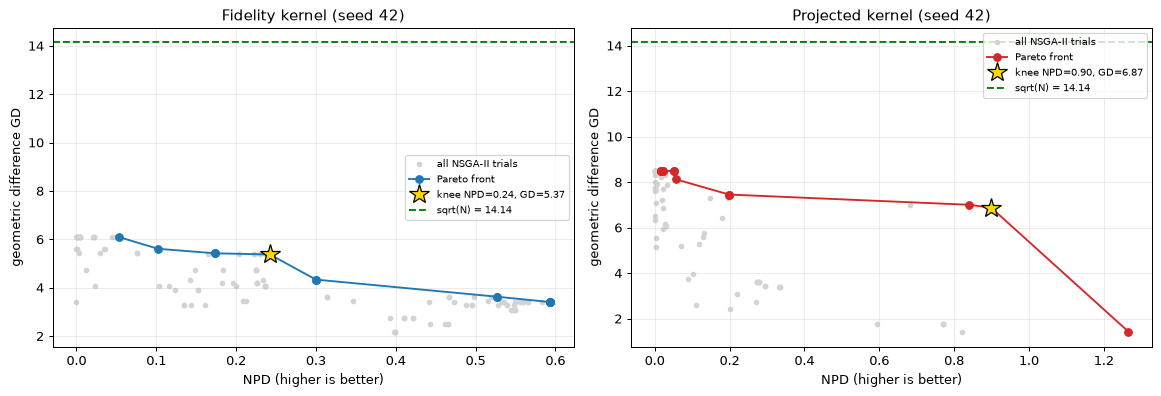

In [20]:
fig_fronts(res)

### 6.3 Geometric difference and NPD against the test AUC of every explored configuration (cf. Figures 3 and 4)

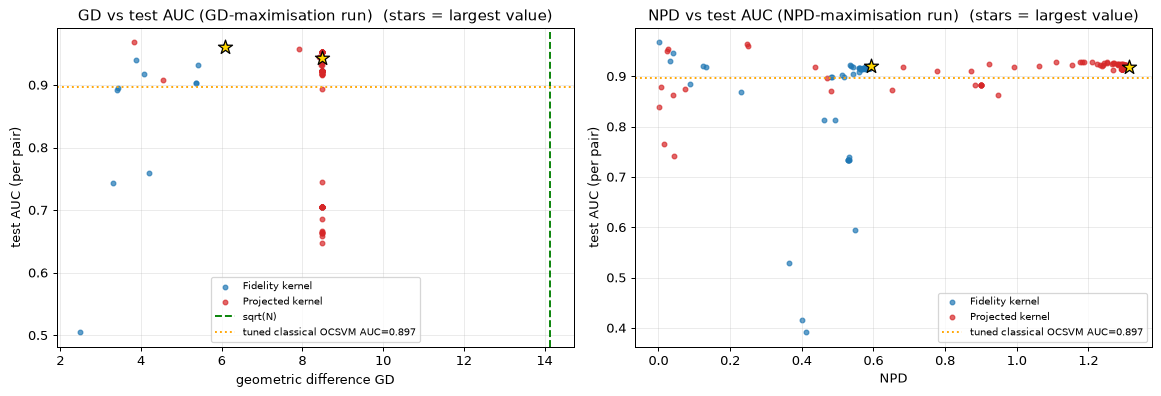

,kernel,run,n_trials,spearman_rho,p_value,best_test_auc_in_run,share_above_baseline
0,Fidelity kernel,NPD-maximisation,150,0.570,0.0000,0.967,0.907
1,Fidelity kernel,GD-maximisation,150,0.919,0.0000,0.960,0.967
2,Projected kernel,NPD-maximisation,100,0.161,0.1091,0.964,0.840
3,Projected kernel,GD-maximisation,100,0.315,0.0014,0.968,0.720


All explored configurations of the six searches, by encoding (test AUC is evaluation only):


configs  mean_NPD  mean_GD  mean_test_AUC  min_test_AUC  \
kernel enc                                                                    
fid    CNOT              36     0.125    4.942          0.937         0.899   
       Hamiltonian      182     0.557    3.425          0.895         0.500   
       IQP               32     0.386    2.791          0.551         0.364   
       Z                200     0.037    5.903          0.946         0.725   
pqk    CNOT              88     0.059    7.589          0.924         0.765   
       Hamiltonian       14     0.221    7.532          0.833         0.722   
       IQP               54     0.106    6.652          0.943         0.500   
       Z                144     0.764    4.200          0.879         0.648   

                    share_AUC_below_0_5  
kernel enc                               
fid    CNOT                       0.000  
       Hamiltonian                0.000  
       IQP                        0.375  
       Z                          0.000  
pqk    CNOT                       0.000  
       Hamiltonian                0.000  
       IQP                        0.000  
       Z                          0.000

In [21]:
fig_gd_npd_vs_auc(res)
display(corr_table(res))
allt = pd.concat([r.assign(kernel=k, run=o) for (k, o), r in res["runs"].items()])
print("All explored configurations of the six searches, by encoding (test AUC is evaluation only):")
display(allt.groupby(["kernel", "enc"]).agg(configs=("npd", "size"), mean_NPD=("npd", "mean"), mean_GD=("gd", "mean"), mean_test_AUC=("test_auc", "mean"),
                                           min_test_AUC=("test_auc", "min"), share_AUC_below_0_5=("test_auc", lambda s: (s < 0.5).mean())).round(3))

### 6.4 Confusion matrices of the selected kernels and of the classical baseline

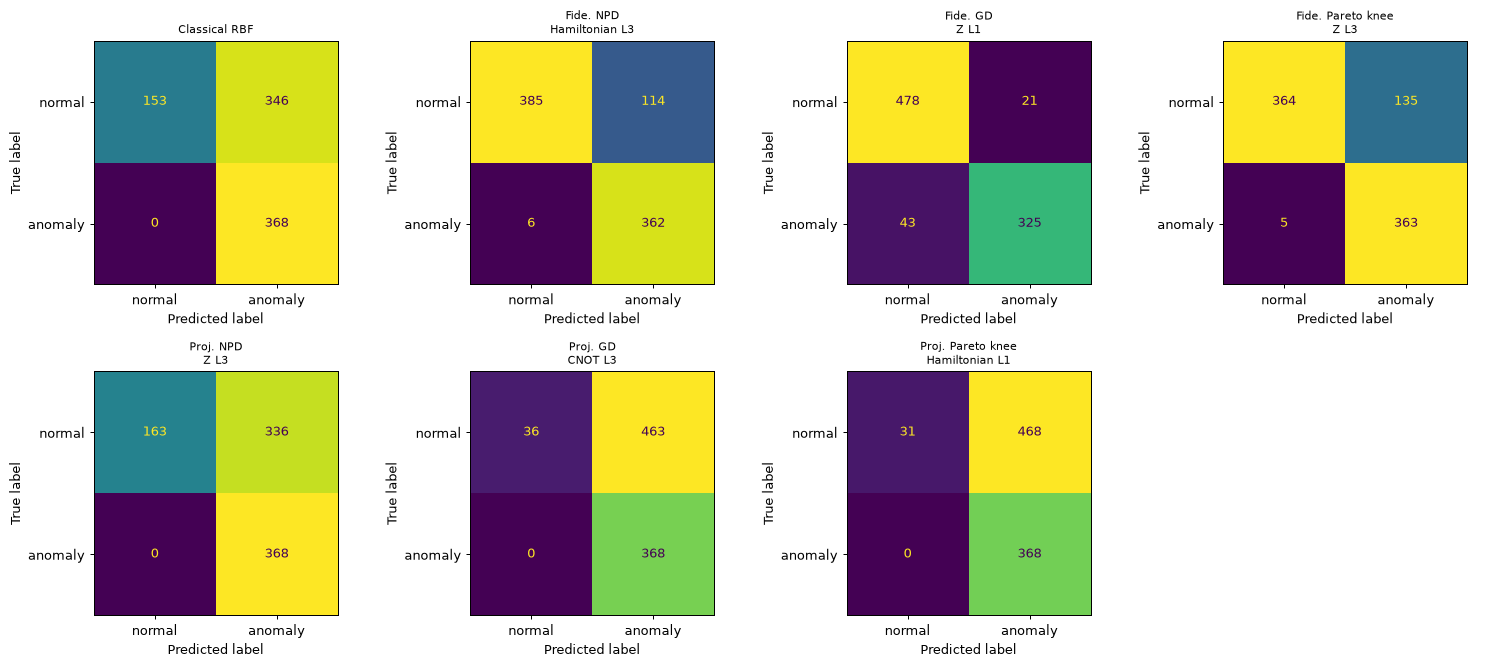

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
def decisions_of(res, cfg):
    return test_decisions(res["bench"], cfg, test_gram(res["bench"], cfg))
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
items = [("Classical RBF", res["cfgC"])] + [(f"{KIND_NAME[k][:4]}. {OBJ_LABEL[o]}", res["selected"][(k, o)]["cfg"]) for k in KINDS for o in OBJECTIVES]
for a, (name, cfg) in zip(axes.ravel(), items):
    dec = decisions_of(res, cfg); dfp = pd.DataFrame(dict(p=res["ds"].pair_test, d=dec, y=res["ds"].y_test)).groupby("p").agg(d=("d", "min"), y=("y", "max"))
    ConfusionMatrixDisplay.from_predictions(dfp.y, (dfp.d < 0).astype(int), display_labels=["normal", "anomaly"], ax=a, colorbar=False)
    a.set_title(name + (f"\n{cfg['enc']} L{cfg['layers']}" if "enc" in cfg else ""), fontsize=9); a.grid(False)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 6.5 Repetition over seeds

In [23]:
rows = []
for s, r in RESULTS.items():
    d = dict(seed=s, classical_AUC=r["metricsC"]["pair"]["auc"])
    for (k, o), sel in r["selected"].items():
        m = (sel.get("metrics_qiskit") or sel["metrics"])["pair"]
        d[f"{k}_{o}_AUC"] = m["auc"]; d[f"{k}_{o}_GD"] = sel["gd"]
    rows.append(d)
SEEDTAB = pd.DataFrame(rows).set_index("seed")
print("Selected encoding and number of layers per seed:")
display(pd.DataFrame({f"{k}_{o}": {s: f"{r['selected'][(k, o)]['cfg']['enc']} L{r['selected'][(k, o)]['cfg']['layers']}" for s, r in RESULTS.items()} for k in KINDS for o in OBJECTIVES}))
display(SEEDTAB.round(3))
if len(SEEDTAB) > 1:
    display(pd.DataFrame({"mean": SEEDTAB.mean(), "std": SEEDTAB.std(ddof=1)}).round(3).T)
else:
    print("FAST_MODE runs one seed; set FAST_MODE = False for the five-seed mean +- std.")

Selected encoding and number of layers per seed:


,fid_npd,fid_gd,fid_joint,pqk_npd,pqk_gd,pqk_joint
42,Hamiltonian L3,Z L1,Z L3,Z L3,CNOT L3,Hamiltonian L1
43,IQP L5,IQP L5,IQP L3,Hamiltonian L2,IQP L5,Hamiltonian L4
44,Hamiltonian L1,Z L2,IQP L5,Hamiltonian L2,IQP L5,IQP L3
45,Hamiltonian L3,IQP L2,IQP L3,Hamiltonian L5,Z L4,Z L4
46,Hamiltonian L3,IQP L5,IQP L3,Hamiltonian L4,IQP L5,Z L4


,classical_AUC,fid_npd_AUC,fid_npd_GD,fid_gd_AUC,fid_gd_GD,fid_joint_AUC,fid_joint_GD,pqk_npd_AUC,pqk_npd_GD,pqk_gd_AUC,pqk_gd_GD,pqk_joint_AUC,pqk_joint_GD
seed,,,,,,,,,,,,,
42,0.897,0.920,3.407,0.948,6.092,0.912,5.374,0.919,1.593,0.943,8.494,0.824,6.872
43,0.889,0.420,7.259,0.412,7.259,0.378,3.983,0.835,5.922,0.947,7.811,0.878,9.914
44,0.857,0.833,3.044,0.948,4.878,0.519,4.513,0.863,2.808,0.948,8.069,0.883,11.491
45,0.883,0.903,2.192,0.383,6.980,0.458,10.906,0.897,16.385,0.839,26.194,0.840,26.194
46,0.863,0.841,2.264,0.590,19.404,0.516,9.609,0.879,10.132,0.939,39.769,0.783,19.880


,classical_AUC,fid_npd_AUC,fid_npd_GD,fid_gd_AUC,fid_gd_GD,fid_joint_AUC,fid_joint_GD,pqk_npd_AUC,pqk_npd_GD,pqk_gd_AUC,pqk_gd_GD,pqk_joint_AUC,pqk_joint_GD
mean,0.878,0.783,3.633,0.656,8.923,0.557,6.877,0.878,7.368,0.923,18.067,0.842,14.870
std,0.017,0.207,2.092,0.278,5.932,0.206,3.159,0.032,6.024,0.047,14.438,0.041,7.957


## Quantum Circuit Architecture

The circuits below are the objects that are executed: `FidelityStatevectorKernel` simulates exactly these `QuantumCircuit`s for the fidelity kernel, and `Statevector` + `partial_trace` is used for the projected kernel. Measurement is not drawn: with exact statevectors the kernel is read from amplitudes. On hardware the fidelity kernel needs a compute-uncompute circuit with measurement of the all-zero outcome, and the projected kernel needs measurements of the one-qubit Pauli expectations (the paper uses classical shadows).

**Assumptions where the paper gives no circuit details** (all marked `# CHOICE:` in the code): the feature angles `x_j` enter the rotations directly (they are already scaled to [0, pi]); the IQP phase carries the factor `-i/2`; the Hamiltonian map uses total time `t = 1`, `T = layers` Trotter steps, nearest-neighbour couplings applied in order 1..n and fixed pseudo-random single-qubit initial states; the CNOT ladder runs from qubit 1 to qubit n. The data angles are circuit parameters; **none of the kernel circuits has trainable parameters** (the kernel hyper-parameters `nu`, `gamma`, number of layers are chosen by search).

### Qubits, depth and parameters of all executed circuits

In [24]:
facts = []
for enc in ENCODINGS:
    for L in range(1, 6):
        f = circuit_facts(feature_map_circuit(enc, L)); facts.append(dict(encoding=enc, layers=L, **f))
display(pd.DataFrame(facts).rename(columns={"data_params": "data-encoding parameters", "trainable_params": "trainable parameters", "size": "gates"}))

,encoding,layers,qubits,depth,gates,data-encoding parameters,trainable parameters,two_qubit_gates
0,Z,1,6,2,12,6,0,0
1,Z,2,6,4,24,6,0,0
2,Z,3,6,6,36,6,0,0
3,Z,4,6,8,48,6,0,0
4,Z,5,6,10,60,6,0,0
5,IQP,1,6,11,27,6,0,15
6,IQP,2,6,19,54,6,0,30
7,IQP,3,6,27,81,6,0,45
8,IQP,4,6,35,108,6,0,60
9,IQP,5,6,43,135,6,0,75


### One drawing per encoding (a single layer; the block is repeated `layers` times)

Z: qubits = 6, depth = 2, trainable parameters = 0, data parameters = 6


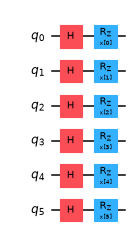

IQP: qubits = 6, depth = 11, trainable parameters = 0, data parameters = 6


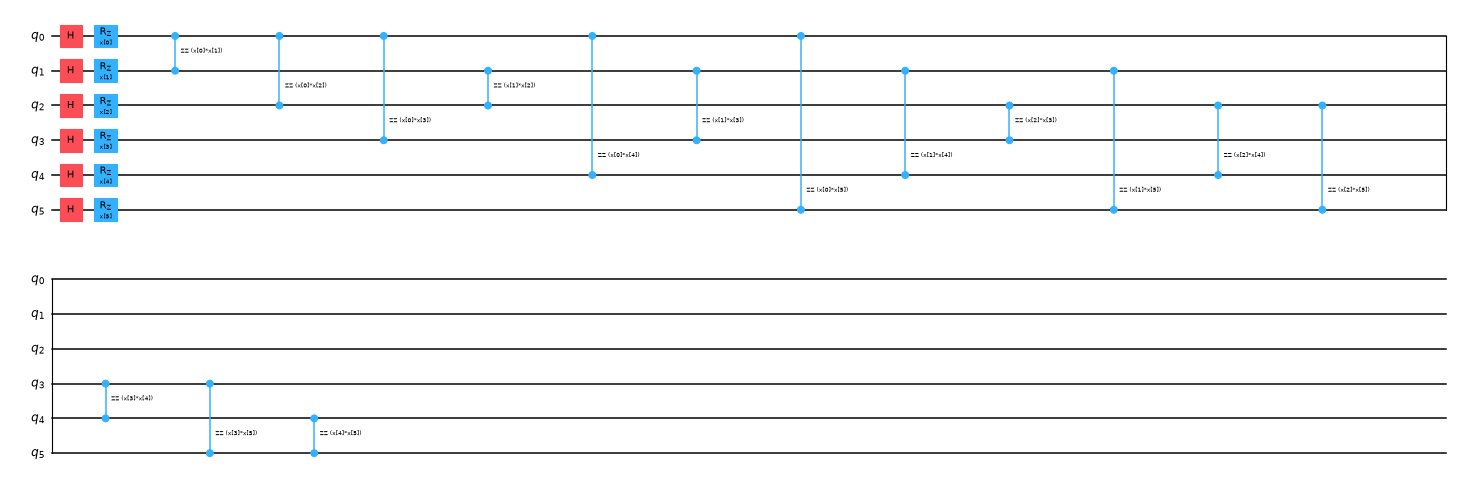

CNOT: qubits = 6, depth = 7, trainable parameters = 0, data parameters = 6


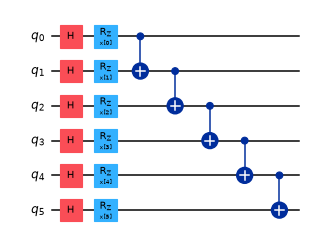

Hamiltonian: qubits = 7, depth = 20, trainable parameters = 0, data parameters = 6


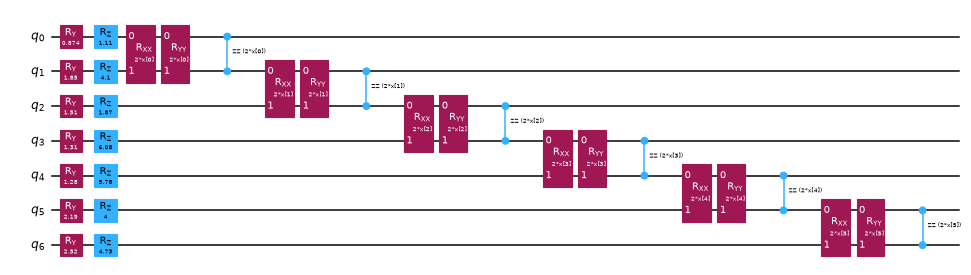

In [25]:
for enc in ENCODINGS:
    qc = feature_map_circuit(enc, 1)
    print(f"{enc}: qubits = {qc.num_qubits}, depth = {qc.depth()}, trainable parameters = 0, data parameters = {qc.num_parameters}")
    fig = qc.draw("mpl", fold=40, scale=0.6); display(fig); plt.close(fig)

### Circuits of the kernels selected for the main seed (one drawing per distinct architecture that is not a single-layer circuit already shown)

Fidelity kernel / NPD-selected: Hamiltonian with 3 layer(s): qubits = 7, depth = 32, gates = 68, two-qubit gates = 54, trainable parameters = 0, data parameters = 6


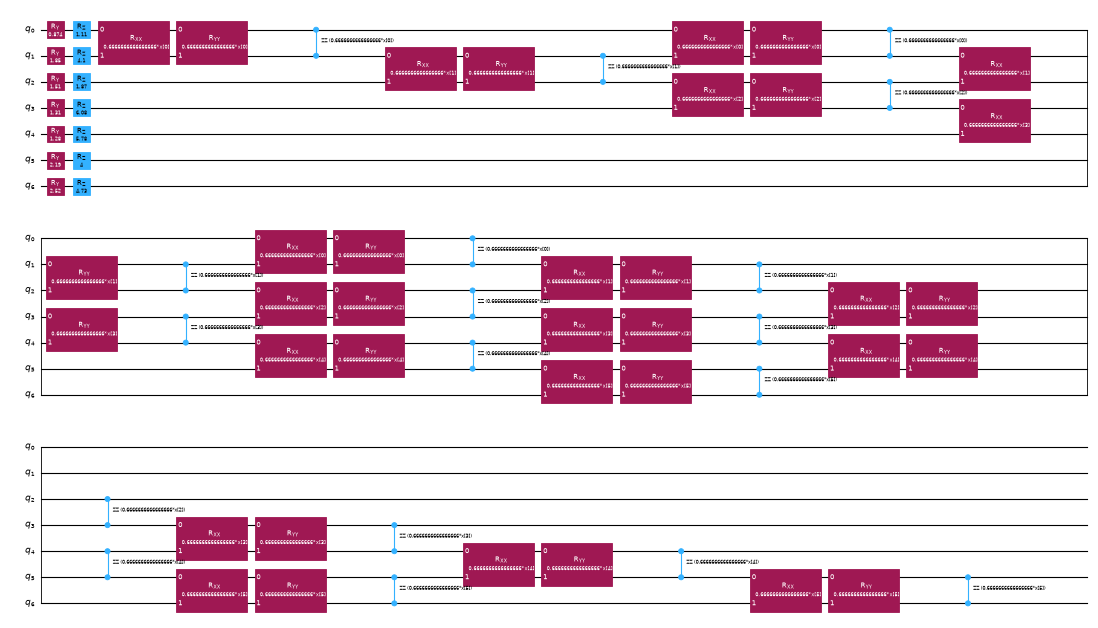

Fidelity kernel / GD-selected: Z with 1 layer(s): qubits = 6, depth = 2, gates = 12, two-qubit gates = 0, trainable parameters = 0, data parameters = 6
Fidelity kernel / Pareto knee-selected: Z with 3 layer(s): qubits = 6, depth = 6, gates = 36, two-qubit gates = 0, trainable parameters = 0, data parameters = 6


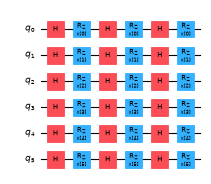

Projected kernel / NPD-selected: Z with 3 layer(s): qubits = 6, depth = 6, gates = 36, two-qubit gates = 0, trainable parameters = 0, data parameters = 6
Projected kernel / GD-selected: CNOT with 3 layer(s): qubits = 6, depth = 15, gates = 51, two-qubit gates = 15, trainable parameters = 0, data parameters = 6


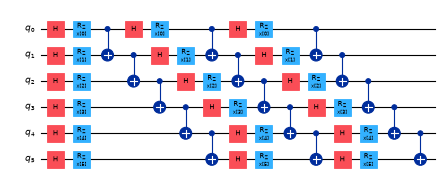

Projected kernel / Pareto knee-selected: Hamiltonian with 1 layer(s): qubits = 7, depth = 20, gates = 32, two-qubit gates = 18, trainable parameters = 0, data parameters = 6


In [26]:
shown = {(e, 1) for e in ENCODINGS}
for (kind, obj), sel in res["selected"].items():
    key = (sel["cfg"]["enc"], sel["cfg"]["layers"])
    qc = feature_map_circuit(*key)
    print(f"{KIND_NAME[kind]} / {OBJ_LABEL[obj]}-selected: {key[0]} with {key[1]} layer(s): qubits = {qc.num_qubits}, depth = {qc.depth()}, "
          f"gates = {qc.size()}, two-qubit gates = {circuit_facts(qc)['two_qubit_gates']}, trainable parameters = 0, data parameters = {qc.num_parameters}")
    if key not in shown:
        shown.add(key); fig = qc.draw("mpl", fold=40, scale=0.45); display(fig); plt.close(fig)

## 7. Side by side with the paper

Verdict rule: AUC and F1 are *reproduced* when within 0.02 of the paper, GD and NPD values when within 25 % (relative); otherwise *not reached* (below) or *exceeded* (above). Qualitative claims are *reproduced* when the statement holds in this notebook's numbers. Rows that need the IQM noise model or the IQM Garnet processor are *cannot be checked*. The main seed (42) carries the verdicts; the other rows summarise the other seeds when `FAST_MODE = False`.

**Outcome in one paragraph.** On the main seed 8 rows are *reproduced*, 16 *exceeded*, 21 *not reached* and 8 *cannot be checked*. The "exceeded" AUC / F1 rows say that the detection task built here from public pcaps is *easier* than the paper's (the tuned classical baseline already reaches AUC 0.86 to 0.90 over the five seeds, against 0.765 in the paper), not that quantum kernels do better. What does carry over: the GD of the fidelity kernels stays below `sqrt(N)` (all three selections on seed 42 and in 4 of 5 seeds, claim Q3) and the identity-limit relation `g^2 = 1/lambda_min(K_C)` holds exactly (Q11). What does not carry over: NPD-selected fidelity kernels beat the classical baseline only in 2 of 5 seeds (Q1), the projected kernels exceed `sqrt(N)` only for some seeds (Q4, Q5, Q9), and the best-AUC model is not the NPD-selected fidelity kernel (Q6). The hardware and noisy-simulator rows cannot be checked here.

In [27]:
PAPER = {   # numbers printed in the paper (Tables III-VII, Sec. IV)
    ("classical", "auc"): 0.765, ("classical", "f1_A"): 0.599, ("classical", "f1_N"): 0.561,
    ("fid", "npd"): dict(auc=0.840, f1_A=0.657, f1_N=0.715, gd=4.297, npd=2.34),
    ("fid", "gd"): dict(auc=0.666, f1_A=0.494, f1_N=0.800, gd=7.14, npd=0.592),
    ("fid", "joint"): dict(auc=0.812, f1_A=0.671, f1_N=0.773, gd=5.94, npd=0.72),
    ("pqk", "npd"): dict(auc=0.777, f1_A=0.599, f1_N=0.563, gd=32.0, npd=2.94),
    ("pqk", "gd"): dict(auc=0.738, f1_A=0.542, f1_N=0.340, gd=272.0, npd=0.603),
    ("pqk", "joint"): dict(auc=0.782, f1_A=0.638, f1_N=0.736, gd=88.6, npd=1.42),
}
PAPER_NOISY_AUC = {("fid", "npd"): 0.790, ("fid", "gd"): 0.752, ("fid", "joint"): 0.798,
                   ("pqk", "npd"): 0.777, ("pqk", "gd"): 0.738, ("pqk", "joint"): 0.647}
PAPER_HW = {"Fidelity (Hamiltonian) on IQM Garnet": (0.532, 0.640, 0.151), "Projected (Z) on IQM Garnet": (0.612, 0.630, 0.656)}
TOL = 0.02          # AUC / F1 tolerance; GD and NPD values: relative tolerance REL_TOL
REL_TOL = 0.25


def verdict_num(nb, paper, tol=TOL, rel=False):
    gap = nb - paper
    ok = abs(gap) <= (tol * abs(paper) if rel else tol)
    return "reproduced" if ok else ("exceeded" if gap > 0 else "not reached")


def build_claims(res, label="seed 42"):
    sel = res["selected"]; mC = res["metricsC"]["pair"]
    nbm = lambda k, key: (sel[k].get("metrics_qiskit") or sel[k]["metrics"])["pair"][key]
    base = mC["auc"]; rows = []
    add = lambda cid, claim, paper, nb, verdict: rows.append(dict(id=cid, claim=claim, paper=paper, notebook=nb, verdict=verdict))
    # --- Table III: tuned classical OCSVM
    for key, nm in (("auc", "AUC"), ("f1_A", "F1(A)"), ("f1_N", "F1(N)")):
        add("C", f"Classical OCSVM {nm}", PAPER[("classical", key)], round(mC[key], 3), verdict_num(mC[key], PAPER[("classical", key)]))
    # --- Table VI (statevector): AUC / F1 per kernel and objective
    for kind in KINDS:
        for obj in OBJECTIVES:
            for key, nm in (("auc", "AUC"), ("f1_A", "F1(A)"), ("f1_N", "F1(N)")):
                p = PAPER[(kind, obj)][key]; v = nbm((kind, obj), key)
                add("VI", f"{KIND_NAME[kind]}, {OBJ_LABEL[obj]}-selected: {nm}", p, round(v, 3), verdict_num(v, p))
    # --- Tables IV/V: geometric difference and NPD of the selected kernels
    for kind in KINDS:
        for obj in OBJECTIVES:
            for key, nm in (("gd", "g_C->Q"), ("npd", "NPD")):
                p = PAPER[(kind, obj)][key]; v = sel[(kind, obj)][key]
                add("IV/V", f"{KIND_NAME[kind]}, {OBJ_LABEL[obj]}-selected: {nm}", p, round(v, 3), verdict_num(v, p, REL_TOL, rel=True))
    # --- qualitative claims
    auc = lambda k: nbm(k, "auc"); gd = lambda k: sel[k]["gd"]
    q = lambda cid, claim, paper, nb, ok: add(cid, claim, paper, nb, "reproduced" if ok else "not reached")
    q("Q1", "NPD-selected fidelity kernel beats the tuned classical baseline (AUC)", "0.840 > 0.765", f"{auc(('fid', 'npd')):.3f} vs {base:.3f}", auc(("fid", "npd")) > base)
    q("Q2", "Pareto(knee)-selected projected kernel exceeds the baseline (AUC)", "0.782 > 0.765", f"{auc(('pqk', 'joint')):.3f} vs {base:.3f}", auc(("pqk", "joint")) > base)
    q("Q3", "Fidelity kernels stay below sqrt(N) in GD for all three selections", f"max 7.14 < {SQRT_N:.2f}", f"max {max(gd(('fid', o)) for o in OBJECTIVES):.2f}", all(gd(("fid", o)) < SQRT_N for o in OBJECTIVES))
    q("Q4", "Projected kernels exceed sqrt(N) in GD for all three selections", f"min 32.0 > {SQRT_N:.2f}", f"min {min(gd(('pqk', o)) for o in OBJECTIVES):.2f}", all(gd(("pqk", o)) > SQRT_N for o in OBJECTIVES))
    q("Q5", "Pareto knee of the projected kernel has g_C->Q > sqrt(N)", "88.6 > 14.14", f"{gd(('pqk', 'joint')):.2f}", gd(("pqk", "joint")) > SQRT_N)
    best = max(((k, auc(k)) for k in sel), key=lambda t: t[1])
    q("Q6", "The best model overall is the NPD-selected fidelity kernel", "fid/NPD 0.840", f"best = {best[0]} ({best[1]:.3f})", best[0] == ("fid", "npd"))
    q("Q7", "Large GD does not help: GD-selected projected AUC <= NPD-selected projected AUC + 0.02", "0.738 vs 0.777", f"{auc(('pqk', 'gd')):.3f} vs {auc(('pqk', 'npd')):.3f}", auc(("pqk", "gd")) <= auc(("pqk", "npd")) + TOL)
    ft = res["runs"][("pqk", "joint")]; fF = res["runs"][("fid", "joint")]
    q("Q8", "Fidelity Pareto front keeps GD <~ 7 (front max GD <= 7.5)", "GD <~ 7", f"max {fF.loc[pareto_mask(fF[['npd', 'gd']].values)].gd.max():.2f}", fF.loc[pareto_mask(fF[["npd", "gd"]].values)].gd.max() <= 7.5)
    q("Q9", "Whole projected Pareto front lies above sqrt(N)", f"all > {SQRT_N:.2f}", f"min {ft.loc[pareto_mask(ft[['npd', 'gd']].values)].gd.min():.2f}", ft.loc[pareto_mask(ft[["npd", "gd"]].values)].gd.min() > SQRT_N)
    for kind in KINDS:
        tr = res["runs"][(kind, "npd")]; r = spearmanr(tr.npd, tr.test_auc).statistic
        q("Q10", f"NPD-AUC relation within the {KIND_NAME[kind].lower()} family is weak (|Spearman| <= 0.3)", "weak", f"rho = {r:.2f}", abs(r) <= 0.3)
    # --- identity-limit identity from Sec. IV B
    I = np.eye(N_TRAIN); g_id = geometric_difference(I, res["KC"]); lam = np.linalg.eigvalsh(res["KC"]).min() + 1e-8
    q("Q11", "K_Q = I gives g^2 = ||K_C^-1|| = 1/lambda_min(K_C)", "identity", f"g^2 = {g_id ** 2:.3f}, 1/lambda_min = {1 / lam:.3f}", np.isclose(g_id ** 2, 1 / lam, rtol=1e-3))
    # --- rows that cannot be checked here
    for (kind, obj), p in PAPER_NOISY_AUC.items():
        add("VI-noisy", f"IQM noisy simulator: {KIND_NAME[kind]}, {OBJ_LABEL[obj]}-selected AUC", p, "-", "cannot be checked")
    for nm, (a, f1a, f1n) in PAPER_HW.items():
        add("VII", f"{nm}: AUC / F1(A) / F1(N)", f"{a} / {f1a} / {f1n}", "-", "cannot be checked")
    df = pd.DataFrame(rows)
    df.insert(0, "run", label)
    return df

In [28]:
CLAIMS = build_claims(res, f"seed {SEED}")
pd.set_option("display.max_colwidth", 90, "display.width", 200)
display(CLAIMS.drop(columns="run"))
print("\nVerdict counts (seed %d):" % SEED); print(CLAIMS.verdict.value_counts().to_string())
if len(RESULTS) > 1:
    allc = pd.concat([build_claims(r, f"seed {s}") for s, r in RESULTS.items()])
    q = allc[allc.id.str.startswith("Q")]
    print("\nQualitative claims: number of seeds (out of %d) in which each claim holds" % len(RESULTS))
    print(q.assign(holds=q.verdict.eq("reproduced")).groupby(["id", "claim"]).holds.sum().to_string())
    num = allc[allc.id.isin(["C", "VI"]) & allc.claim.str.contains("AUC")]
    print("\nAUC rows: share of seeds within 0.02 of the paper")
    print(num.assign(ok=num.verdict.eq("reproduced")).groupby("claim").ok.mean().round(2).to_string())

,id,claim,paper,notebook,verdict
0,C,Classical OCSVM AUC,0.765,0.897,exceeded
1,C,Classical OCSVM F1(A),0.599,0.68,exceeded
2,C,Classical OCSVM F1(N),0.561,0.469,not reached
3,VI,"Fidelity kernel, NPD-selected: AUC",0.84,0.92,exceeded
4,VI,"Fidelity kernel, NPD-selected: F1(A)",0.657,0.858,exceeded
5,VI,"Fidelity kernel, NPD-selected: F1(N)",0.715,0.865,exceeded
6,VI,"Fidelity kernel, GD-selected: AUC",0.666,0.948,exceeded
7,VI,"Fidelity kernel, GD-selected: F1(A)",0.494,0.91,exceeded
8,VI,"Fidelity kernel, GD-selected: F1(N)",0.8,0.937,exceeded
9,VI,"Fidelity kernel, Pareto knee-selected: AUC",0.812,0.912,exceeded



Verdict counts (seed 42):
verdict
not reached          21
exceeded             16
reproduced            8
cannot be checked     8



Qualitative claims: number of seeds (out of 5) in which each claim holds
id   claim                                                                                 
Q1   NPD-selected fidelity kernel beats the tuned classical baseline (AUC)                     2
Q10  NPD-AUC relation within the fidelity kernel family is weak (|Spearman| <= 0.3)            3
     NPD-AUC relation within the projected kernel family is weak (|Spearman| <= 0.3)           4
Q11  K_Q = I gives g^2 = ||K_C^-1|| = 1/lambda_min(K_C)                                        5
Q2   Pareto(knee)-selected projected kernel exceeds the baseline (AUC)                         1
Q3   Fidelity kernels stay below sqrt(N) in GD for all three selections                        4
Q4   Projected kernels exceed sqrt(N) in GD for all three selections                           1
Q5   Pareto knee of the projected kernel has g_C->Q > sqrt(N)                                  2
Q6   The best model overall is the NPD-selected fidelity k

## 8. Reading the paper critically

* **The data differ, so absolute numbers are not comparable.** The paper's flow table is private. Here every external flow of the infected CTU-13 machine is labelled anomalous (spam and click-fraud flows as well as C&C traffic), and many of them are short SYN-only flows with zero packet-length spread; the normal flows come from the browsing sessions of a few hosts. The tuned classical OCSVM therefore reaches AUC 0.857 to 0.897 over five seeds (paper: 0.765). Rows marked "exceeded" for AUC and F1 reflect an easier task; they are no evidence for or against quantum kernels. The six features are those of the paper, but the packet-level definitions (FFT of the forward byte count in 1-second bins, service port as lower port, 1 ms duration floor) are our reading of a terse description.
* **A single run is not enough to support the headline.** The paper reports one split and one search per objective. Over five seeds the NPD-selected fidelity kernel has AUC 0.42 to 0.92 (mean 0.78, std 0.21) and beats the tuned classical baseline in 2 of 5 seeds; the Pareto-knee fidelity kernel ranges from 0.38 to 0.91. The paper itself notes that NPD "identifies a good region rather than ranking configurations"; our seeds show how large the within-region spread is. A bootstrap over the 867 evaluation pairs gives an AUC interval of about +-0.02, so differences such as 0.782 versus 0.765 or 0.790 versus 0.777 in the paper are inside the resolution of a single evaluation.
* **What NPD rewards.** NPD measures how well a model separates held-out normal flows from an axis-aligned Gaussian cloud in the scaled box. It does not know what a botnet flow looks like. The table of explored configurations in section 6.3 shows the consequence for the fidelity kernel on seed 42: the IQP encodings (two-qubit phases up to about 10 rad, hence oscillatory kernels) reach a mean NPD of 0.39, ten times that of the Z map (0.04), yet their mean test AUC is 0.55 and 12 of 32 explored IQP configurations rank botnet flows *below* normal flows (AUC below 0.5), while the Z, CNOT and Hamiltonian maps all stay above 0.5. The Pareto knee picked an IQP circuit in 4 of 5 seeds (NPD alone once), which is why the fidelity Pareto-knee AUC collapses on those seeds.
* **GD is a property of the pair (quantum kernel, classical reference).** The reference is the RBF kernel tuned by NPD, whose bandwidth changes from seed to seed (gamma 3.5 to 10.5 here). On seed 42 its smallest eigenvalue is 8e-3, so even a kernel equal to the identity matrix cannot exceed `g` of about 11, below `sqrt(N) = 14.14`; the paper's 272 corresponds to a smallest eigenvalue near 1e-5. In other seeds the projected kernels do exceed `sqrt(N)` (26 and 40 for the GD-selected kernel on seeds 45 and 46), again by driving `gamma` to the edge of its range. The paper says this itself: a large GD can come from one classical hyper-parameter and is necessary but not sufficient for an advantage. `g << sqrt(N)` is a sufficient condition for a classical model to match the quantum one; `g > sqrt(N)` certifies nothing about performance.
* **Exact simulation of 6-7 qubits.** A 7-qubit state has 128 amplitudes; all kernels here are cheap classical computations and shot noise or hardware noise is not modelled. The paper's noisy-simulator and IQM Garnet rows (AUC 0.532 and 0.612, classical shadows of size 100) need the IQM noise model and the processor and are therefore "cannot be checked".
* **Label use.** Labels enter only in the final evaluation and in the per-trial test AUC drawn in the figures; the search and the selection see only the 200 training flows and 40 generated points. Preprocessing is fitted on the training flows. The only label-dependent design decision is the anomaly definition itself, which is fixed by the capture.
* **What this reproduction found.** (i) The fidelity-kernel GD stays below `sqrt(N)` as in the paper (seed 42: 3.4, 6.1, 5.4). (ii) The projected-kernel GD exceeds `sqrt(N)` only in some seeds, and not at all on the main seed. (iii) Large GD is not harmful here: the GD-selected kernels have the highest AUC on several seeds (fidelity 0.948 and projected 0.943 on seed 42), but the ordering changes with the seed, so none of the paper's rankings (fidelity NPD above projected, Pareto knee in between) is stable. (iv) The NPD-AUC rank correlation within a family is weak (|rho| below 0.3) on 4 of 5 seeds for the projected kernels and on 3 of 5 seeds for the fidelity kernels (rho = 0.57 for the fidelity family on the main seed). The paper's methodological message, that NPD and GD must be read together and that neither alone certifies a quantum advantage, is supported; its specific numbers are not reproducible from public data.

## 9. Exercises

1. **Change the anomaly definition.** Restrict the botnet class to flows with at least 20 packets (a crude beacon filter) and rerun. Does the NPD-selected fidelity kernel still beat the classical baseline? Which encodings are selected?
2. **Bandwidth of the fidelity kernel.** Multiply all angles by a bandwidth `b` in `{0.25, 0.5, 1, 2}` before encoding and add `b` to the search space. The paper cites bandwidth tuning as a remedy for exponential concentration; does it change the GD of the fidelity kernel?
3. **Identity limit.** Plot the GD of the projected kernel against `gamma` for a fixed encoding and compare with `sqrt(1/lambda_min(K_C))`. At which `gamma` does the kernel become the identity matrix?
4. **A better classical reference.** Replace the RBF reference by the best of RBF, Laplacian and polynomial kernels (tuned by NPD) and recompute all GD values. How many selected quantum kernels stay above `sqrt(N)`?
5. **Beaconing-aware feature map.** Add a feature that measures periodicity (for example the ratio of the largest FFT peak to the mean spectrum of the forward packet times) and one qubit for it. Does the label-free NPD still pick a useful region?